# A1 · Preparación y Auditoría de Calidad de Datos
**Proyecto 01 - Retail Intelligence (RetailVenture C.A.)** · Tópicos Especiales para la Gestión de Datos · Prof. Armen Djenanian

| Integrante | Cédula |
|---|---|
| Daniel Verschuur | 30.906.270 |
| Valeria León | 30.906.837 |
| Edgar Paz | 30.843.445 |
| Javier Delmoral | 30.823.959 |
| Gilberto Moncada | 29.631.382 |

Este notebook cubre la actividad **A1** del enunciado, y solo eso:

1. **Cargar los seis datasets** e identificar **nulos, duplicados, outliers y registros inconsistentes** (p. ej. devoluciones sin transacción de origen, campañas con fechas posteriores a la compra).
2. **Documentar las decisiones de limpieza y transformación**, justificando cada una técnicamente.
3. **Calcular y reportar las métricas de calidad** del dato: **completitud, consistencia, unicidad y oportunidad** por cada dataset.

### Cómo está organizado

Los CSV originales de la raíz **nunca se modifican**: son la evidencia sobre la que se mide la calidad. El notebook tiene dos mitades separadas por una línea divisoria: hasta el §5 solo **mide**; desde el §6 **transforma**, y el §7 es la única sección que escribe en `data/clean/`.

| § | Contenido |
|---|---|
| 0 | Entorno y parámetros centralizados |
| 1 | Carga y perfilado: tipos, nulos (explícitos y disfrazados) y vocabulario de las categóricas |
| 2 | Duplicados: PK, filas idénticas, duplicados lógicos |
| 3 | Outliers en las variables continuas (IQR y z-score) y verificación de si son errores |
| 4 | Registros inconsistentes: integridad referencial y verificaciones de consistencia R01–R25 |
| — | **▼ A partir de aquí se construye `data/clean/` ▼** |
| 5 | Métricas de calidad por dataset: completitud, unicidad, consistencia y oportunidad |
| 6 | Limpieza justificada y efecto antes/después |
| 7 | Exportación de las tablas limpias y validaciones |
| 8 | Supuestos y limitaciones |

## 0. Entorno y parámetros
Todos los umbrales, SLA y tolerancias viven en **una sola celda**: cambiar un parámetro cambia de forma consistente todas las reglas y métricas que lo usan.

In [1]:
# ============================================================================
# §0 · Entorno: importaciones, opciones de visualización y rutas del proyecto
# ----------------------------------------------------------------------------
# Todas las importaciones viven aquí, para que el notebook se ejecute de arriba
# abajo sin importar nada a mitad de camino.
# ============================================================================
import sys, platform, warnings
import numpy as np
import pandas as pd
import scipy, matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)   # ruido de pandas/scipy; no altera resultados
pd.set_option('display.max_columns', 60)                   # que las tablas anchas se vean completas
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 90)
pd.set_option('display.max_rows', 120)

def localizar_raiz():
    # Sube desde el directorio de trabajo hasta la carpeta que contiene los CSV:
    # así el notebook funciona igual abierto desde la raíz o desde notebooks/.
    cwd = Path.cwd().resolve()
    for base in [cwd, *cwd.parents]:
        if (base / 'transacciones.csv').exists() and (base / 'clientes.csv').exists():
            return base
    raise FileNotFoundError('No se encontró la carpeta del proyecto (transacciones.csv / clientes.csv).')

RAIZ = localizar_raiz()
RAW = RAIZ                                   # CSV originales (solo lectura en todo el notebook)
CLEAN = RAIZ / 'data' / 'clean'              # salida de la limpieza (se escribe únicamente en el §7)
FIG = RAIZ / 'outputs' / 'figuras'
TAB = RAIZ / 'outputs' / 'tablas'
for carpeta in (CLEAN, FIG, TAB):
    carpeta.mkdir(parents=True, exist_ok=True)   # idempotente: no falla si ya existen

def guardar_tabla(df, nombre, index=False):
    # utf-8-sig: al abrir el CSV en Excel (Windows) los acentos se ven bien
    df.to_csv(TAB / nombre, index=index, encoding='utf-8-sig')

def guardar_figura(fig, nombre):
    fig.savefig(FIG / nombre, dpi=150, bbox_inches='tight')   # 150 dpi: legible sin pesar de más

# Traza de reproducibilidad: la última fila confirma desde qué carpeta se leyó el dato.
pd.Series({'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
           'scipy': scipy.__version__, 'matplotlib': matplotlib.__version__,
           'raíz del proyecto': str(RAIZ)}, name='entorno').to_frame()

,entorno
python,3.13.5
pandas,2.3.3
numpy,2.3.3
scipy,1.18.1
matplotlib,3.10.8
raíz del proyecto,C:\Users\danie\Documents\6to-7mo sem - 202715\Topicos Especiales Para la Gestion de Da...


In [2]:
# ---------------- Parámetros y supuestos (única fuente de verdad) ----------------
# Ningún umbral se escribe "a mano" dentro de las reglas: todos se leen de aquí,
# de modo que cambiar uno se propaga de forma consistente a verificaciones y métricas.
FECHA_INICIO, FECHA_CORTE = pd.Timestamp('2023-01-01'), pd.Timestamp('2024-12-31')   # ventana del enunciado
VENTANA_ATRIBUCION_D = 30       # días tras el envío en que una compra se atribuye a la campaña (R19/R21)
SLA_CRM_HRS = 168               # 7 días: respuesta CRM esperada (R14 y tabla de decisiones)
SLA_DEVOLUCION_D = 30           # días máximos entre compra y devolución (R23)
TOL_MONTO = 0.02                # USD: redondeo a centavos de precio x cantidad x (1 - descuento) (R05)
TOL_DESC = 0.005                # 0,5 pp: tolerancia al comparar descuentos (R21)
TOL_MARGEN_PP = 0.1             # 0,1 pp: tolerancia del margen_bruto_pct del catálogo (R09)
Q_WINS = 0.99                   # percentil de winsorización del tiempo de respuesta CRM (§6)
EDAD_MIN, EDAD_MAX = 18, 100    # rango plausible de edad (R01)
BINS_EDAD = [17, 25, 35, 45, 55, 65, 100]            # cortes de los rangos de edad de dim_cliente
ETIQ_EDAD = ['18-25', '26-35', '36-45', '46-55', '56-65', '66+']
MOTIVOS_NO_RECUPERABLES = ['Producto_defectuoso', 'Fraude_reportado']   # el producto devuelto no vuelve al inventario
# Tokens que parecen dato pero no lo son: base de la detección de nulos disfrazados (§1).
TOKENS_NULOS = {'', 'na', 'n/a', 'nan', 'null', 'none', 'no especificado', 'desconocido', 'sin dato', '-'}
# Correspondencia 1:1 entre tipo de campaña y canal: es lo que valida R17.
CANAL_POR_CAMPANA = {'email_descuento': 'email', 'email_fidelizacion': 'email', 'push_reactivacion': 'push_app',
                     'sms_oferta_flash': 'sms', 'social_ads': 'redes_sociales'}


## 1. Carga y perfilado
**Objetivo:** conocer la forma de cada dataset (tamaño, tipos, nulos, cardinalidad) antes de juzgar su calidad. Los DataFrames se cargan una sola vez en `raw` y **no se vuelven a modificar**; todo lo que sigue trabaja con copias o con columnas derivadas nuevas.

In [3]:
# Diccionario mínimo de la carga: qué columnas son fechas (se parsean al leer) y
# cuál es la clave primaria de cada tabla (se usa en §2 y en las métricas de §5).
fechas = {
    'clientes': ['fecha_registro'], 'transacciones': ['fecha'], 'productos': [],
    'devoluciones': ['fecha_devolucion'], 'interacciones_crm': ['fecha'], 'campanas_marketing': ['fecha_envio'],
}
pk = {
    'clientes': 'cliente_id', 'transacciones': 'transaccion_id', 'productos': 'producto_id',
    'devoluciones': 'devolucion_id', 'interacciones_crm': 'interaccion_id', 'campanas_marketing': 'campana_id',
}
# Una sola lectura: 'raw' es la evidencia y no se modifica en ningún punto del notebook.
raw = {n: pd.read_csv(RAW / f'{n}.csv', parse_dates=cols, encoding='utf-8') for n, cols in fechas.items()}
cli, trx, prod, dev, crm, cam = (raw[n] for n in fechas)   # alias cortos para el resto del análisis

# Volumen y memoria por dataset: confirma que los seis archivos cargaron completos.
pd.DataFrame({n: {'filas': len(df), 'columnas': df.shape[1], 'memoria_KB': round(df.memory_usage(deep=True).sum() / 1024)}
              for n, df in raw.items()}).T

,filas,columnas,memoria_KB
clientes,8000,7,2477
transacciones,50000,10,16248
productos,318,7,86
devoluciones,6724,6,1694
interacciones_crm,4684,7,1402
campanas_marketing,8820,8,2307


In [4]:
def perfil(df):
    # Perfil por columna: tipo, nulos explícitos, cardinalidad y 4 ejemplos.
    # Una fila por columna; el índice es el nombre de la columna.
    return pd.DataFrame({
        'tipo': df.dtypes.astype(str),
        'nulos': df.isna().sum(),
        'nulos_%': (df.isna().mean() * 100).round(2),
        'distintos': df.nunique(),
        'ejemplos': [list(df[c].dropna().astype(str).unique()[:4]) for c in df.columns],
    })

# Un perfil por dataset. El nombre del dataset va como primera columna (no como
# separador impreso), así cada tabla se identifica sola y el CSV guardado es uno solo.
perfiles = []
for n, df in raw.items():
    p = perfil(df).reset_index(names='columna')
    p.insert(0, 'dataset', n)
    perfiles.append(p)
    display(p.set_index(['dataset', 'columna']))
# Se exporta el perfil completo de los seis datasets en un único CSV auditable.
guardar_tabla(pd.concat(perfiles).assign(ejemplos=lambda d: d.ejemplos.astype(str)), 'a1_perfil_columnas.csv')

tipo  nulos  nulos_%  distintos                                                ejemplos
dataset  columna                                                                                                             
clientes cliente_id                 object      0      0.0       8000                [CLI00001, CLI00002, CLI00003, CLI00004]
         edad                        int64      0      0.0         55                                        [65, 23, 19, 55]
         genero                     object      0      0.0          3                                 [M, F, No especificado]
         ciudad                     object      0      0.0          8             [Caracas, Valencia, Mérida, Puerto La Cruz]
         segmento                   object      0      0.0          5              [Esporádico, Frecuente, Premium, Inactivo]
         fecha_registro     datetime64[ns]      0      0.0        730        [2023-01-26, 2024-07-12, 2024-09-08, 2024-04-04]
         canal_adquisicion          object      0      0.0          6  [Tienda_física, Orgánico_web, Referido, Email_campaña]

tipo  nulos  nulos_%  distintos                                                    ejemplos
dataset       columna                                                                                                               
transacciones transaccion_id           object      0      0.0      50000            [TRX0000001, TRX0000002, TRX0000003, TRX0000004]
              cliente_id               object      0      0.0       7608                    [CLI03713, CLI07240, CLI00568, CLI06802]
              fecha            datetime64[ns]      0      0.0        731            [2024-01-11, 2023-08-27, 2024-07-20, 2024-04-02]
              producto_id              object      0      0.0        318                        [PRD0189, PRD0219, PRD0306, PRD0262]
              cantidad                  int64      0      0.0          5                                                [1, 2, 4, 3]
              precio_unitario         float64      0      0.0        317                               [6.72, 340.03, 33.94, 268.47]
              descuento               float64      0      0.0        311                                [0.044, 0.077, 0.116, 0.063]
              monto_neto              float64      0      0.0      24840                               [6.42, 313.85, 60.01, 251.56]
              canal                    object      0      0.0          3                          [tienda_fisica, online, app_movil]
              metodo_pago              object      0      0.0          5  [efectivo, tarjeta_credito, tarjeta_debito, transferencia]

tipo  nulos  nulos_%  distintos                                                                                   ejemplos
dataset   columna                                                                                                                                        
productos producto_id        object      0      0.0        318                                                       [PRD0001, PRD0002, PRD0003, PRD0004]
          nombre             object      0      0.0        318  [Electrónica_Prod_0001, Electrónica_Prod_0002, Electrónica_Prod_0003, Electrónica_Prod...
          categoria          object      0      0.0          6                           [Electrónica, Ropa_y_Calzado, Hogar_y_Deco, Alimentos_y_Bebidas]
          subcategoria       object      0      0.0         24                                        [Smartphones, Computadoras, Audio, Accesorios_tech]
          costo             float64      0      0.0        318                                                           [936.26, 503.65, 367.79, 712.66]
          precio_lista      float64      0      0.0        317                                                          [1186.64, 566.54, 439.42, 821.04]
          margen_bruto_pct  float64      0      0.0        223                                                                   [21.1, 11.1, 16.3, 13.2]

tipo  nulos  nulos_%  distintos                                                                          ejemplos
dataset      columna                                                                                                                                      
devoluciones devolucion_id             object      0      0.0       6724                                      [DEV000001, DEV000002, DEV000003, DEV000004]
             transaccion_id            object      0      0.0       6724                                  [TRX0000015, TRX0000020, TRX0000021, TRX0000022]
             cliente_id                object      0      0.0       3679                                          [CLI03995, CLI07310, CLI07961, CLI00809]
             motivo                    object      0      0.0          7  [No_cumple_expectativas, Producto_defectuoso, Error_en_pedido, Fraude_reportado]
             monto_devuelto           float64      0      0.0       5240                                                  [57.68, 1030.45, 753.14, 129.64]
             fecha_devolucion  datetime64[ns]      0      0.0        727                                  [2024-08-04, 2024-06-30, 2024-07-07, 2024-01-21]

tipo  nulos  nulos_%  distintos                                                   ejemplos
dataset           columna                                                                                                                   
interacciones_crm interaccion_id                object      0      0.0       4684           [INT0000001, INT0000002, INT0000003, INT0000004]
                  cliente_id                    object      0      0.0       2400                   [CLI04116, CLI05281, CLI03254, CLI05096]
                  tipo                          object      0      0.0          4           [soporte_tecnico, consulta, queja, felicitacion]
                  fecha                 datetime64[ns]      0      0.0        729           [2024-01-22, 2023-05-14, 2023-08-19, 2024-03-21]
                  canal                         object      0      0.0          5                [chat_web, email, redes_sociales, telefono]
                  resolucion                    object      0      0.0          4  [escalado, resuelto, sin_resolver, parcialmente_resuelto]
                  tiempo_respuesta_hrs         float64      0      0.0        733                                    [9.8, 32.5, 34.9, 13.7]

tipo  nulos  nulos_%  distintos                                                             ejemplos
dataset            columna                                                                                                                           
campanas_marketing campana_id                  object      0      0.0       8820                     [CAM0000001, CAM0000002, CAM0000003, CAM0000004]
                   cliente_id                  object      0      0.0       4800                             [CLI02349, CLI07137, CLI07079, CLI02681]
                   tipo_campana                object      0      0.0          5  [social_ads, email_fidelizacion, email_descuento, sms_oferta_flash]
                   fecha_envio         datetime64[ns]      0      0.0        731                     [2024-08-31, 2024-06-22, 2024-05-01, 2023-12-14]
                   canal_campana               object      0      0.0          4                               [redes_sociales, email, sms, push_app]
                   abierto                      int64      0      0.0          2                                                               [0, 1]
                   convertido                   int64      0      0.0          2                                                               [0, 1]
                   descuento_ofrecido         float64      0      0.0          6                                               [0.0, 0.05, 0.1, 0.15]

**Nulos explícitos:** ninguno en los seis datasets. Hay que buscar, además, **nulos disfrazados**: valores que ocupan la celda pero no aportan información (`No especificado`, cadenas vacías, `N/A`, espacios sobrantes).

In [5]:
# Nulos disfrazados: tokens que ocupan la celda pero no informan ('No especificado',
# 'N/A', '-', ...) y valores con espacios sobrantes (que romperían el vocabulario de §1.1).
filas = []
for n, df in raw.items():
    for c in df.select_dtypes(include=['object', 'string']).columns:
        s = df[c].astype(str).str.strip().str.lower()          # se compara en minúsculas y sin espacios
        k = int(s.isin(TOKENS_NULOS).sum())
        espacios = int((df[c].astype(str) != df[c].astype(str).str.strip()).sum())
        if k or espacios:                                       # solo se listan las columnas afectadas
            filas.append({'dataset': n, 'columna': c, 'nulos_disfrazados': k, 'con_espacios': espacios})
nulos_disf = pd.DataFrame(filas)
# Total por dataset: es la cifra que entra en la métrica de completitud (§5).
NULOS_DISFRAZADOS = {n: int(g.nulos_disfrazados.sum()) for n, g in nulos_disf.groupby('dataset')}
nulos_disf

,dataset,columna,nulos_disfrazados,con_espacios
0,clientes,genero,433,0


Único nulo disfrazado: `clientes.genero = "No especificado"`. **No se imputa:** el género no puede inferirse de otras variables sin introducir un sesgo, así que se conserva como categoría propia. No hay espacios sobrantes ni variantes de mayúsculas en las categorías.

### 1.1 Variables categóricas: niveles y frecuencias
Se listan las variables categóricas de **baja cardinalidad** (≤ 25 niveles; se excluyen los identificadores y el texto libre) con su vocabulario y la frecuencia de cada valor.


In [ ]:
# Perfil categórico: se recorren las variables de texto de baja cardinalidad (se excluyen
# los IDs y el texto libre) y se lista su vocabulario con la frecuencia de cada valor.
filas = []
for n, df in raw.items():
    for c in df.select_dtypes(include=['object', 'string']).columns:
        if c.endswith('_id') or df[c].nunique() > 25:          # IDs y texto libre no son categóricas
            continue
        vc = df[c].value_counts()
        filas.append({'dataset': n, 'variable': c, 'niveles': len(vc),
                      'valores (n)': ' | '.join(f'{k} ({v:,})' for k, v in vc.items())})
categoricas_tab = pd.DataFrame(filas)
categoricas_tab


,dataset,variable,niveles,valores (n)
0,clientes,genero,3,"F (3,834) | M (3,733) | No especificado (433)"
1,clientes,ciudad,8,"Caracas (3,170) | Maracaibo (1,457) | Valencia (1,201) | Barquisimeto (793) | Mérida (..."
2,clientes,segmento,5,"Esporádico (2,827) | Frecuente (2,422) | Inactivo (1,136) | Nuevo (810) | Premium (805)"
3,clientes,canal_adquisicion,6,"Redes_sociales (2,036) | Tienda_física (2,032) | Orgánico_web (1,552) | Referido (1,20..."
4,transacciones,canal,3,"tienda_fisica (22,343) | online (19,220) | app_movil (8,437)"
5,transacciones,metodo_pago,5,"tarjeta_credito (14,984) | tarjeta_debito (14,026) | efectivo (10,916) | transferencia..."
6,productos,categoria,6,Electrónica (53) | Ropa_y_Calzado (53) | Hogar_y_Deco (53) | Alimentos_y_Bebidas (53) ...
7,productos,subcategoria,24,Maquillaje (22) | Ropa_femenina (19) | Decoración (18) | Computadoras (18) | Ropa_masc...
8,devoluciones,motivo,7,"No_cumple_expectativas (2,298) | Producto_defectuoso (1,890) | Error_en_pedido (887) |..."
9,interacciones_crm,tipo,4,"queja (2,081) | consulta (1,496) | soporte_tecnico (874) | felicitacion (233)"


## 2. Duplicados
**Objetivo:** detectar registros repetidos en tres niveles de exigencia creciente:
1. **Clave primaria duplicada** (el identificador se repite).
2. **Fila idéntica** (todas las columnas iguales).
3. **Duplicado lógico** (distinto ID pero mismo hecho de negocio, según una clave natural definida por dataset).

In [7]:
# Clave natural (duplicado lógico) de cada dataset: dos filas con la misma clave
# describen el mismo hecho de negocio aunque tengan distinto ID.
claves_logicas = {
    'clientes': None,
    'transacciones': ['cliente_id', 'fecha', 'producto_id', 'cantidad', 'monto_neto', 'canal'],
    'productos': ['nombre'],
    'devoluciones': ['transaccion_id'],          # una transacción no debería devolverse dos veces
    'interacciones_crm': ['cliente_id', 'tipo', 'fecha', 'canal'],
    'campanas_marketing': ['cliente_id', 'tipo_campana', 'fecha_envio'],
}
CASI_DUP_TRX = ['cliente_id', 'fecha', 'producto_id']      # misma persona, mismo día, mismo producto (R24)

# Los tres niveles de exigencia del §2 se calculan en la misma pasada:
# PK duplicada | fila idéntica | duplicado lógico según la clave natural.
filas = []
for n, df in raw.items():
    filas.append({'dataset': n, 'registros': len(df),
                  'pk_duplicada': int(df[pk[n]].duplicated().sum()),
                  'filas_identicas': int(df.duplicated().sum()),
                  'dup_logicos': int(df.duplicated(claves_logicas[n]).sum()) if claves_logicas[n] else 0,
                  'clave_logica': ', '.join(claves_logicas[n]) if claves_logicas[n] else '—'})
tabla_dup = pd.DataFrame(filas)
guardar_tabla(tabla_dup, 'a1_duplicados.csv')
tabla_dup

,dataset,registros,pk_duplicada,filas_identicas,dup_logicos,clave_logica
0,clientes,8000,0,0,0,—
1,transacciones,50000,0,0,0,"cliente_id, fecha, producto_id, cantidad, monto_neto, canal"
2,productos,318,0,0,0,nombre
3,devoluciones,6724,0,0,0,transaccion_id
4,interacciones_crm,4684,0,0,0,"cliente_id, tipo, fecha, canal"
5,campanas_marketing,8820,0,0,1,"cliente_id, tipo_campana, fecha_envio"


In [8]:
# El único duplicado lógico del §2 se inspecciona fila a fila: mismo cliente, mismo
# tipo de campaña y misma fecha, pero distinto ID, descuento y resultado. Eso descarta
# el error de carga y apunta a un doble envío (o a una prueba A/B).
dup_campana = cam[cam.duplicated(['cliente_id', 'tipo_campana', 'fecha_envio'], keep=False)]
dup_campana

,campana_id,cliente_id,tipo_campana,fecha_envio,canal_campana,abierto,convertido,descuento_ofrecido
4457,CAM0004458,CLI01899,email_descuento,2024-06-13,email,0,0,0.15
4459,CAM0004460,CLI01899,email_descuento,2024-06-13,email,1,1,0.05


**Lectura:** no hay claves primarias repetidas ni filas idénticas en ningún dataset, así que el riesgo de doble conteo por error de carga es nulo. Solo aparece **1 duplicado lógico**: un cliente recibió dos `email_descuento` el mismo día con descuentos distintos (15 % y 5 %) y solo convirtió el segundo. Como tienen ID, descuento y resultado distintos, no es una fila repetida por error (parece un doble envío o una prueba A/B): se conservan los dos y se marcan (`flag_envio_duplicado`), porque borrar uno cambiaría la tasa de conversión del descuento eliminado.

En `transacciones`, los casi-duplicados por (cliente, fecha, producto) son **0**, de modo que la verificación R24 no tiene nada que marcar.

## 3. Outliers
**Objetivo:** buscar valores extremos **solo donde la medida tiene sentido**.

| Tipo de variable | Variables | Tratamiento |
|---|---|---|
| Cuantitativa **continua** | `edad`, `precio_unitario`, `monto_neto`, `costo`, `precio_lista`, `monto_devuelto`, `tiempo_respuesta_hrs` | Resumen, **IQR** y **z-score**, boxplot |
| Cuantitativa **acotada** | `descuento` [0,1), `margen_bruto_pct` [0,100] | Validación de rango; sin z-score |
| **Conteo** / **ordinal** | `cantidad` (1–5), `descuento_ofrecido` (6 niveles) | Tabla de frecuencias |
| **Binaria** | `abierto`, `convertido` | Proporción de eventos |
| Nominal / fecha / ID | resto | Dominio (§1.1), reglas temporales (§4) |


In [9]:
# Tipología de medidas (§3): estos cuatro conjuntos son la fuente de verdad de la
# clasificación y deciden a qué variables se les puede aplicar IQR / z-score.
CONTINUAS = {('clientes', 'edad'), ('transacciones', 'precio_unitario'), ('transacciones', 'monto_neto'),
             ('productos', 'costo'), ('productos', 'precio_lista'), ('devoluciones', 'monto_devuelto'),
             ('interacciones_crm', 'tiempo_respuesta_hrs')}
ACOTADAS = {('transacciones', 'descuento'), ('productos', 'margen_bruto_pct')}
DISCRETAS = {('transacciones', 'cantidad'), ('campanas_marketing', 'descuento_ofrecido')}
BINARIAS = {('campanas_marketing', 'abierto'), ('campanas_marketing', 'convertido')}
assert len(CONTINUAS | ACOTADAS | DISCRETAS | BINARIAS) == 13, 'la tipología debe cubrir las 13 variables numéricas'

# Variables acotadas: se valida el rango declarado en lugar de buscar outliers,
# porque con soporte limitado por diseño un extremo es el borde del dominio.
RANGO_VALIDO = {('transacciones', 'descuento'): (0, 0.999), ('productos', 'margen_bruto_pct'): (0, 100)}
for (n_, c_), (lo, hi) in RANGO_VALIDO.items():
    assert raw[n_][c_].between(lo, hi).all(), f'{n_}.{c_} tiene valores fuera de [{lo}, {hi}]'

### 3.1 Variables continuas: resumen y outliers
Resumen por **IQR** (1,5 × RIQ) y **z-score** (|z| > 3). Como los montos son muy asimétricos a la derecha, el z-score se reporta pero se interpreta con cautela: la media y la DE están arrastradas por la cola, así que el **criterio principal es el IQR**.

In [10]:
# Para cada variable continua se calculan, en una sola función, el resumen descriptivo
# y las dos medidas de outlier: IQR (1,5 x RIQ) y z-score (|z| > 3). Ver el markdown
# del §3.1: la asimetría decide cuál de las dos se usa como criterio principal.
VAR_CONT = {f'{n}.{c}': raw[n][c] for n, c in sorted(CONTINUAS)}

def resumen_continua(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr                  # vallas de Tukey
    z = (s - s.mean()) / s.std()                             # z-score clásico
    return {'n': len(s), 'min': s.min(), 'p1': s.quantile(.01), 'mediana': s.median(), 'media': s.mean(), 'p99': s.quantile(.99),
            'max': s.max(), 'DE': s.std(), 'asimetría': s.skew(), 'lim_inf_IQR': lo, 'lim_sup_IQR': hi,
            'outliers_IQR': int(((s < lo) | (s > hi)).sum()), '%_outliers_IQR': ((s < lo) | (s > hi)).mean() * 100,
            'outliers_z>3': int((z.abs() > 3).sum())}

tabla_out = pd.DataFrame({k: resumen_continua(v) for k, v in VAR_CONT.items()}).T
guardar_tabla(tabla_out.reset_index(names='variable').round(3), 'a1_outliers.csv')
tabla_out.round(2)   # la tabla es la evidencia del §3.1; el CSV es su versión exportada

,n,min,p1,mediana,media,p99,max,DE,asimetría,lim_inf_IQR,lim_sup_IQR,outliers_IQR,%_outliers_IQR,outliers_z>3
clientes.edad,8000.0,18.00,18.00,45.00,45.22,72.00,72.00,16.12,-0.02,-11.00,101.00,0.0,0.00,0.0
devoluciones.monto_devuelto,6724.0,3.16,8.94,171.59,376.93,2842.27,5552.95,554.45,3.54,-501.77,1028.71,615.0,9.15,173.0
interacciones_crm.tiempo_respuesta_hrs,4684.0,0.40,1.30,12.00,19.34,109.33,518.60,23.61,5.45,-19.10,48.90,352.0,7.51,82.0
productos.costo,318.0,2.68,4.93,69.30,145.51,952.74,996.20,186.21,2.28,-205.92,414.58,27.0,8.49,8.0
productos.precio_lista,318.0,4.04,6.73,116.92,204.47,1129.10,1186.64,230.30,1.91,-324.93,658.22,16.0,5.03,7.0
transacciones.monto_neto,50000.0,3.10,7.53,163.99,347.86,2422.11,5840.92,504.78,3.53,-504.38,998.50,4138.0,8.28,1195.0
transacciones.precio_unitario,50000.0,4.04,6.73,116.60,205.34,1132.89,1186.64,230.49,1.89,-327.30,662.62,2509.0,5.02,1086.0


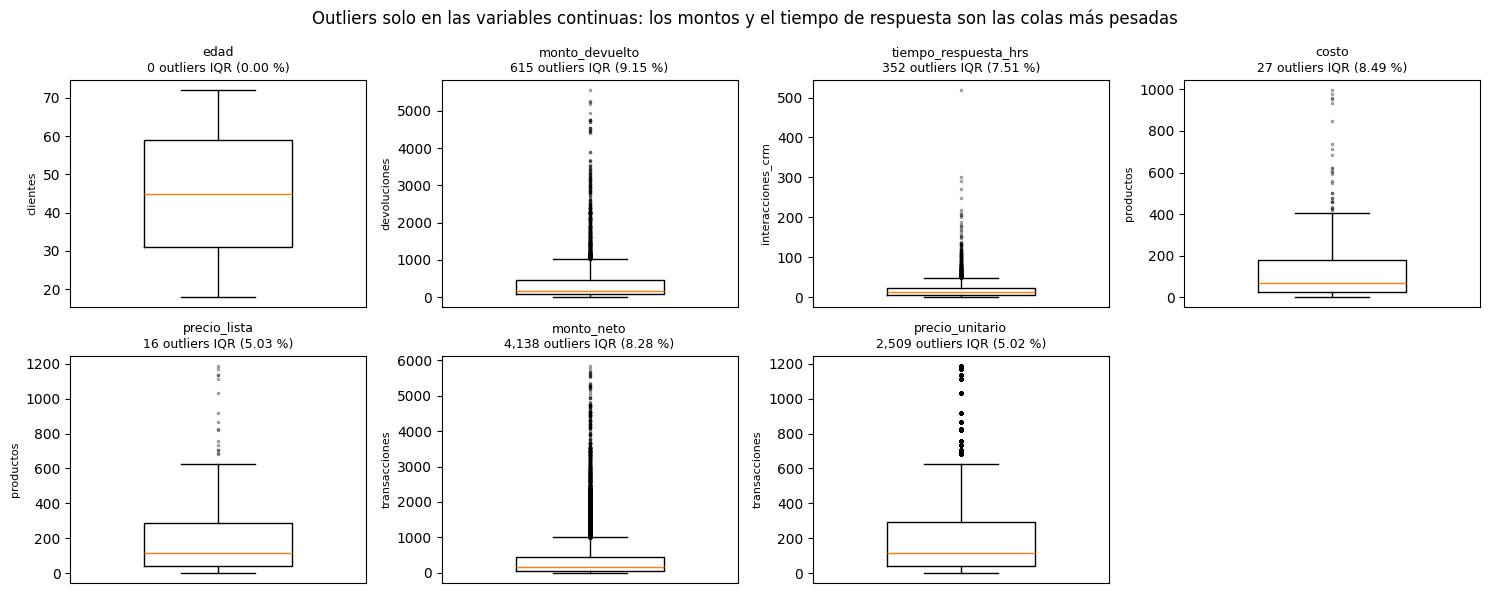

In [11]:
# Boxplot en escala original, solo de las siete variables continuas: es donde el
# criterio IQR tiene sentido (seis de las siete son magnitudes monetarias/tiempo).
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, (k, s) in zip(axes.flat, VAR_CONT.items()):
    n, var = k.split('.')
    ax.boxplot(s.values, widths=.5, flierprops=dict(marker='.', markersize=3, alpha=.4, color='#C44E52'))
    pct = tabla_out.loc[k, '%_outliers_IQR']
    # El título de cada panel repite la cifra de la tabla del §3.1 (una sola fuente de verdad).
    ax.set_title(f'{var}\n{int(tabla_out.loc[k, "outliers_IQR"]):,} outliers IQR ({pct:.2f} %)', fontsize=9)
    ax.set_ylabel(n, fontsize=8); ax.set_xticks([])
axes.flat[-1].axis('off')
fig.suptitle('Outliers solo en las variables continuas: los montos y el tiempo de respuesta son las colas más pesadas', fontsize=12)
plt.tight_layout(); guardar_figura(fig, 'a1_outliers_boxplot.png'); plt.show()

### 3.2 ¿Los outliers son errores o registros legítimos?
Un outlier estadístico no es un error. Cada uno se contrasta con la **identidad aritmética de la venta**: si el monto reconstruido `precio × cantidad × (1 − descuento)` coincide con `monto_neto`, es una venta real de un producto caro. También se mide **cuánto pesan** en el ingreso y en el margen, porque de eso depende la decisión de conservarlos.

**Resultado:** el límite IQR de `monto_neto` es **998,50 USD** y lo superan **4.138 ventas** (8,28 % de las transacciones), que concentran el **39,91 % del ingreso** y el **31,03 % del margen bruto**. **Ninguna** de las 4.138 deja de cumplir la identidad aritmética (0 no cuadran) y se concentran en Electrónica (64,6 %), Hogar_y_Deco (28,2 %) y Deportes (7,2 %): es el catálogo caro, no un error de captura. En `tiempo_respuesta_hrs`, 15 de 4.684 respuestas superan las 168 h (máximo 518,6 h; p99 = 109,3 h).

In [12]:
# Umbral IQR de monto_neto y enriquecimiento de la venta con su categoría y su costo:
# sin el costo no se puede medir cuánto margen aportan los valores extremos.
q1, q3 = trx.monto_neto.quantile([.25, .75]); LIM_MONTO = q3 + 1.5 * (q3 - q1)       # umbral IQR de monto_neto
tx = trx.merge(prod[['producto_id', 'categoria', 'costo']], on='producto_id', how='left')
tx['es_outlier'] = tx.monto_neto > LIM_MONTO
tx['margen'] = tx.monto_neto - tx.cantidad * tx.costo
# Identidad aritmética de la venta: si se cumple, el monto es reconstruible y no un error de carga.
cuadra = np.isclose(tx.monto_neto, tx.precio_unitario * tx.cantidad * (1 - tx.descuento), atol=TOL_MONTO)

# Peso de los outliers frente al total: cuántas ventas son y cuánto ingreso y margen representan.
peso = pd.DataFrame({
    'transacciones': [int(tx.es_outlier.sum()), len(tx)],
    '%_transacciones': [tx.es_outlier.mean() * 100, 100.0],
    'ingreso_USD': [tx.loc[tx.es_outlier, 'monto_neto'].sum(), tx.monto_neto.sum()],
    '%_ingreso': [tx.loc[tx.es_outlier, 'monto_neto'].sum() / tx.monto_neto.sum() * 100, 100.0],
    'margen_bruto_USD': [tx.loc[tx.es_outlier, 'margen'].sum(), tx.margen.sum()],
    '%_margen': [tx.loc[tx.es_outlier, 'margen'].sum() / tx.margen.sum() * 100, 100.0],
}, index=['outliers (monto_neto > límite IQR)', 'total']).round(2)
display(peso)

# Distribución por categoría: si fueran errores de carga, aparecerían repartidos al
# azar; concentrarse en el catálogo caro es lo que se espera de ventas legítimas.
out_cat = (tx[tx.es_outlier].categoria.value_counts().rename('outliers').to_frame()
           .assign(pct_outliers=lambda d: (d.outliers / d.outliers.sum() * 100).round(1)))
display(out_cat)

# Demostración (=0): ningún outlier deja de cumplir la identidad aritmética de la venta.
assert cuadra[tx.es_outlier].all(), 'hay outliers que no reconstruyen precio × cantidad × (1 − descuento)'

,transacciones,%_transacciones,ingreso_USD,%_ingreso,margen_bruto_USD,%_margen
outliers (monto_neto > límite IQR),4138,8.28,6942142.97,39.91,1337520.71,31.03
total,50000,100.00,17392987.48,100.00,4310329.05,100.00


,outliers,pct_outliers
categoria,,
Electrónica,2672,64.6
Hogar_y_Deco,1167,28.2
Deportes,299,7.2


### 3.3 Decisión sobre los outliers

| Variable | Diagnóstico | Decisión |
|---|---|---|
| `monto_neto`, `precio_unitario`, `monto_devuelto`, `costo`, `precio_lista` | Muy asimétricas a la derecha. Los outliers del IQR se concentran en Electrónica y **su monto cuadra exactamente** con precio × cantidad × (1 − descuento): son ventas reales de productos caros, no errores de carga. | **Se conservan.** Se marcan con `flag_outlier_monto`; en los análisis de A2 se reporta la mediana junto a la media. |
| `tiempo_respuesta_hrs` | Distribución con cola larga; los valores altos son casos escalados (positivos y plausibles), no errores. | **Se conservan:** son señal de mal servicio, justo lo que analiza A3. Se marca el incumplimiento del SLA (`flag_respuesta_extrema`) y se crea una versión *winsorizada* para los promedios. |
| `edad` | Dentro del rango plausible (18–72 años). | Sin acción. |
| `descuento`, `margen_bruto_pct` | Dentro de su rango válido. Sin z-score por tener soporte acotado. | Sin acción. |
| `cantidad`, `descuento_ofrecido` | `cantidad` toma 1–5 unidades. `descuento_ofrecido` son 6 niveles de diseño. Un valor alto es la cola del conteo, no un dato anómalo. | Sin acción ni marca. |
| `abierto`, `convertido` | Proporciones (variables binarias). | Sin acción. |

## 4. Registros inconsistentes
**Objetivo:** encontrar registros que, aun sin ser nulos ni duplicados, **contradicen a otro dato o a la coherencia del propio registro**. Se evalúan dos familias: integridad referencial (claves foráneas) y verificaciones de consistencia/temporales (R01–R25). Las verificaciones se escriben como **función pura** (`construir_reglas`) para poder aplicarlas idénticamente al dato crudo (§4–§5) y al limpio (§6).

### 4.1 Integridad referencial (claves foráneas)
Es el caso que el enunciado pone como ejemplo: *"devoluciones sin transacción de origen"*.

In [13]:
def integridad(cli, trx, prod, dev, crm, cam):
    # Una fila es válida si TODAS sus claves foráneas existen en la tabla padre.
    # El resultado es un booleano por registro, con el mismo índice que el dataset:
    # así se puede combinar con las verificaciones del §4.2 para la consistencia (§5).
    return {
        'clientes': pd.Series(True, index=cli.index),
        'transacciones': trx.cliente_id.isin(cli.cliente_id) & trx.producto_id.isin(prod.producto_id),
        'productos': pd.Series(True, index=prod.index),
        'devoluciones': dev.transaccion_id.isin(trx.transaccion_id) & dev.cliente_id.isin(cli.cliente_id),
        'interacciones_crm': crm.cliente_id.isin(cli.cliente_id),
        'campanas_marketing': cam.cliente_id.isin(cli.cliente_id),
    }

# Las seis relaciones del modelo, con el par (columna hija, columna padre) a contrastar.
FK = [('transacciones.cliente_id → clientes', trx.cliente_id, cli.cliente_id),
      ('transacciones.producto_id → productos', trx.producto_id, prod.producto_id),
      ('devoluciones.transaccion_id → transacciones', dev.transaccion_id, trx.transaccion_id),
      ('devoluciones.cliente_id → clientes', dev.cliente_id, cli.cliente_id),
      ('interacciones_crm.cliente_id → clientes', crm.cliente_id, cli.cliente_id),
      ('campanas_marketing.cliente_id → clientes', cam.cliente_id, cli.cliente_id)]
fk = pd.DataFrame([(r, int((~hijo.isin(padre)).sum()), len(hijo)) for r, hijo, padre in FK], columns=['relación', 'huérfanos', 'total'])
guardar_tabla(fk, 'a1_integridad_referencial.csv')
fk

,relación,huérfanos,total
0,transacciones.cliente_id → clientes,0,50000
1,transacciones.producto_id → productos,0,50000
2,devoluciones.transaccion_id → transacciones,0,6724
3,devoluciones.cliente_id → clientes,0,6724
4,interacciones_crm.cliente_id → clientes,0,4684
5,campanas_marketing.cliente_id → clientes,0,8820


La integridad referencial es **perfecta**: no hay devoluciones sin transacción de origen ni registros que apunten a clientes o productos inexistentes. El problema de consistencia no está en las claves, sino en las **fechas y en los indicadores de negocio** (§4.2).

### 4.2 Verificaciones de consistencia (R01–R25)
Cada verificación devuelve `True` cuando el registro **cumple**. Algunas solo aplican a un subconjunto (p. ej. R21 solo a conversiones con compra atribuible); en la tabla de resultados se reporta cuántos registros son *aplicables*.

Estas 25 verificaciones **no son reglas dictadas por la empresa**, sino el **criterio operativo con el que se mide la dimensión de consistencia** del punto 5. No todas tienen el mismo estatus:

- **12 estructurales o aritméticas** (R02, R04–R06, R08–R12, R14, R18, R25): se deducen del diccionario de campos del enunciado y de la aritmética del negocio (`monto_neto = cantidad × precio × (1 − descuento)`, `costo < precio_lista`, `convertido ⇒ abierto`, dominios de las categóricas). No requieren juicio.
- **4 temporales sobre `fecha_registro`** (R03, R07, R16, R20): su validez depende de qué signifique ese campo, y el propio dato la contradice (§4.3); por eso la limpieza lo sustituye por `fecha_alta_efectiva`.
- **9 con una decisión de negocio** (R01, R13, R15, R17, R19, R21, R22, R23, R24): cinco dependen de constantes visibles en §0 (edad 18–100, mapa canal↔tipo de campaña, ventana de atribución, tolerancia de descuento y plazo de devolución) y el resto se apoya en la semántica del campo (una felicitación no tiene resolución; no hay talla fuera de ropa; una devolución es por el monto completo de la línea).

El catálogo siguiente lista las 25 verificaciones con su dimensión y su dataset; la celda posterior las codifica en un único diccionario indexado por dataset, con la convención «`True` = cumple», y en una función que las evalúa; al ser una **función pura**, el §6.1 podrá aplicarla también al dato limpio sin duplicar código. El resultado de esa evaluación es la tabla del apartado siguiente, y el §4.3 lee las filas que fallan.


**Catálogo de las 25 verificaciones.** Cada fila es una regla, con el dataset o los datasets a los que se aplica y su **dimensión**, es decir, la categoría de origen con la que el notebook la clasifica.


| # | Dataset | Verificación (el registro cumple si…) | Dimensión |
|---|---|---|---|
| R01 | `clientes` | edad entre 18 y 100 | decisión de negocio |
| R02 | `clientes` | fecha de alta dentro del período | estructural/aritmética |
| R03 | `clientes` | fecha de alta ≤ primera compra | temporal (fecha_registro) |
| R04 | `transacciones` | precio_unitario = precio_lista del catálogo | estructural/aritmética |
| R05 | `transacciones` | monto_neto = cant × precio × (1 − desc) | estructural/aritmética |
| R06 | `transacciones` | cantidad > 0 y descuento en [0, 1) | estructural/aritmética |
| R07 | `transacciones` | fecha de compra ≥ fecha de alta del cliente | temporal (fecha_registro) |
| R08 | `productos` | costo < precio_lista | estructural/aritmética |
| R09 | `productos` | margen_bruto_pct = (precio − costo)/precio (±0.1 pp) | estructural/aritmética |
| R10 | `devoluciones` | cliente coincide con el de la transacción | estructural/aritmética |
| R11 | `devoluciones` | fecha_devolucion ≥ fecha de compra | estructural/aritmética |
| R12 | `devoluciones` | monto_devuelto ≤ monto_neto | estructural/aritmética |
| R13 | `devoluciones` | motivo "Talla_incorrecta" solo en Ropa_y_Calzado | decisión de negocio |
| R14 | `interacciones_crm` | tiempo_respuesta_hrs > 0 | estructural/aritmética |
| R15 | `interacciones_crm` | felicitación sin estado de resolución | decisión de negocio |
| R16 | `interacciones_crm` | fecha ≥ fecha de alta del cliente | temporal (fecha_registro) |
| R17 | `campanas_marketing` | canal coherente con tipo de campaña | decisión de negocio |
| R18 | `campanas_marketing` | convertido ⇒ abierto | estructural/aritmética |
| R19 | `campanas_marketing` | convertido ⇒ compra en ≤30 días tras el envío | decisión de negocio |
| R20 | `campanas_marketing` | fecha_envio ≥ fecha de alta del cliente | temporal (fecha_registro) |
| R21 | `campanas_marketing` | descuento ofrecido = descuento aplicado (conversión verificable) | decisión de negocio |
| R22 | `devoluciones` | devolución por el monto completo de la línea | decisión de negocio |
| R23 | `devoluciones` | días a devolución entre 0 y 30 | decisión de negocio |
| R24 | `transacciones` | sin casi-duplicados (cliente, fecha, producto) | decisión de negocio |
| R25 | `transacciones`, `devoluciones`, `interacciones_crm`, `campanas_marketing` | fecha dentro de la ventana de análisis | estructural/aritmética |

**Dos notas para leer el catálogo con la tabla de resultados:**

- **R21 es la única con denominador propio:** solo se evalúa en campañas `convertido = 1` con compra atribuible dentro de la ventana (179 de 8.820 envíos). En el resto, `aplicables` es el total de filas del dataset.
- **R25 se instancia una vez por dataset** (en los 4 que tienen fecha de evento: transacciones, devoluciones, CRM y campañas). Por eso el catálogo tiene **25 reglas** y la tabla de resultados del §4.2 tiene **28 comprobaciones**: 25 + 3 instancias extra de R25.
- La columna `dimensión` de este catálogo es la misma que la columna `categoria` de la tabla de resultados; un `assert` de esa celda comprueba que hay 25 códigos distintos con reparto exacto **12 / 4 / 9**.


In [14]:
def construir_reglas(cli, trx, prod, dev, crm, cam, reg):
    """Devuelve (reglas, aplicables, aux). reglas[dataset][regla] = array booleano (True = cumple).
    reg: Serie cliente_id -> fecha de alta que usan las reglas temporales (fecha_registro en el crudo).

    Es una FUNCIÓN PURA: no modifica los DataFrames que recibe. Eso permite aplicarla
    al dato crudo (§4) y al limpio (§6.1) y comparar los dos resultados con el mismo código.
    'aplicables' solo se necesita donde el denominador no es el total de filas (R21).
    """
    # --- Inspecciones auxiliares que comparten varias reglas ---
    primera = trx.groupby('cliente_id').fecha.min()          # primera compra observada por cliente
    # Devoluciones enriquecidas con su transacción y la categoría del producto (R10–R13, R22, R23).
    # El assert protege el grano: el cruce no debe duplicar ni perder devoluciones.
    dv = (dev.merge(trx[['transaccion_id', 'cliente_id', 'fecha', 'monto_neto', 'producto_id']], on='transaccion_id', how='left', suffixes=('', '_trx'))
             .merge(prod[['producto_id', 'categoria']], on='producto_id', how='left'))
    assert len(dv) == len(dev), 'el cruce de devoluciones no debe cambiar el número de filas'
    tp = trx.merge(prod, on='producto_id', how='left')        # venta + catálogo (R04, R05, R09)
    # Atribución de campañas: compras del mismo cliente dentro de la ventana posterior al envío.
    # 'con_compra' es el conjunto de campañas con al menos una compra atribuible (R19).
    cx = cam[['campana_id', 'cliente_id', 'fecha_envio']].merge(trx[['cliente_id', 'fecha', 'monto_neto', 'descuento']], on='cliente_id')
    cx = cx[(cx.fecha >= cx.fecha_envio) & (cx.fecha <= cx.fecha_envio + pd.Timedelta(days=VENTANA_ATRIBUCION_D))]
    con_compra = set(cx.campana_id)
    # Campañas en las que el descuento aplicado en la ventana coincide con el ofrecido (R21).
    cxo = cx.merge(cam[['campana_id', 'descuento_ofrecido']], on='campana_id')
    camp_desc_ok = set(cxo.loc[(cxo.descuento - cxo.descuento_ofrecido).abs() <= TOL_DESC, 'campana_id'])    # --- Arrays alineados por posición: fecha de alta de cada fila y ayudas ---
    r_cli, r_trx, r_crm, r_cam = (d.cliente_id.map(reg).values for d in (cli, trx, crm, cam))
    en_vent = lambda s: s.between(FECHA_INICIO, FECHA_CORTE)                       # R25
    dias_dev = (dv.fecha_devolucion - dv.fecha).dt.days                            # R23
    aplica21 = ((cam.convertido == 1) & cam.campana_id.isin(con_compra)).values    # denominador de R21

    # --- Las 25 verificaciones, agrupadas por dataset ---
    # Convención: cada array vale True cuando el registro CUMPLE, de modo que
    # "incumplen = (~ok).sum()" y la consistencia se obtiene con un AND por fila.
    reglas = {
      'clientes': {
        f'R01 edad entre {EDAD_MIN} y {EDAD_MAX}': cli.edad.between(EDAD_MIN, EDAD_MAX),
        'R02 fecha de alta dentro del período': pd.Series(r_cli).between(FECHA_INICIO, FECHA_CORTE),
        'R03 fecha de alta ≤ primera compra': ~(cli.cliente_id.map(primera).values < r_cli),
      },
      'transacciones': {
        'R04 precio_unitario = precio_lista del catálogo': np.isclose(tp.precio_unitario, tp.precio_lista, atol=0.01),
        'R05 monto_neto = cant × precio × (1 − desc)': np.isclose(trx.monto_neto, trx.cantidad * trx.precio_unitario * (1 - trx.descuento), atol=TOL_MONTO),
        'R06 cantidad > 0 y descuento en [0, 1)': (trx.cantidad > 0) & trx.descuento.between(0, 0.999),
        'R07 fecha de compra ≥ fecha de alta del cliente': trx.fecha.values >= r_trx,
        'R24 sin casi-duplicados (cliente, fecha, producto)': ~trx.duplicated(CASI_DUP_TRX, keep=False),
        'R25 fecha dentro de la ventana de análisis': en_vent(trx.fecha),
      },
      'productos': {
        'R08 costo < precio_lista': prod.costo < prod.precio_lista,
        f'R09 margen_bruto_pct = (precio − costo)/precio (±{TOL_MARGEN_PP} pp)': ((prod.precio_lista - prod.costo) / prod.precio_lista * 100 - prod.margen_bruto_pct).abs() <= TOL_MARGEN_PP,
      },      'devoluciones': {
        'R10 cliente coincide con el de la transacción': dv.cliente_id == dv.cliente_id_trx,
        'R11 fecha_devolucion ≥ fecha de compra': dv.fecha_devolucion >= dv.fecha,
        'R12 monto_devuelto ≤ monto_neto': dv.monto_devuelto <= dv.monto_neto + 0.01,
        'R13 motivo "Talla_incorrecta" solo en Ropa_y_Calzado': ~((dv.motivo == 'Talla_incorrecta') & (dv.categoria != 'Ropa_y_Calzado')),
        'R22 devolución por el monto completo de la línea': np.isclose(dv.monto_devuelto, dv.monto_neto, atol=0.01),
        f'R23 días a devolución entre 0 y {SLA_DEVOLUCION_D}': dias_dev.between(0, SLA_DEVOLUCION_D),
        'R25 fecha dentro de la ventana de análisis': en_vent(dev.fecha_devolucion),
      },
      'interacciones_crm': {
        'R14 tiempo_respuesta_hrs > 0': crm.tiempo_respuesta_hrs > 0,
        'R15 felicitación sin estado de resolución': ~((crm.tipo == 'felicitacion') & ~crm.resolucion.isin(['no_aplica']) & crm.resolucion.notna()),
        'R16 fecha ≥ fecha de alta del cliente': crm.fecha.values >= r_crm,
        'R25 fecha dentro de la ventana de análisis': en_vent(crm.fecha),
      },
      'campanas_marketing': {
        'R17 canal coherente con tipo de campaña': cam.canal_campana == cam.tipo_campana.map(CANAL_POR_CAMPANA),
        'R18 convertido ⇒ abierto': ~((cam.convertido == 1) & (cam.abierto == 0)),
        f'R19 convertido ⇒ compra en ≤{VENTANA_ATRIBUCION_D} días tras el envío': ~((cam.convertido == 1) & ~cam.campana_id.isin(con_compra)),
        'R20 fecha_envio ≥ fecha de alta del cliente': cam.fecha_envio.values >= r_cam,
        'R21 descuento ofrecido = descuento aplicado (conversión verificable)': ~aplica21 | cam.campana_id.isin(camp_desc_ok).values,
        'R25 fecha dentro de la ventana de análisis': en_vent(cam.fecha_envio),
      },
    }
    # Se fuerza dtype bool (algunas expresiones devuelven Series/arrays mixtos) y se
    # declara el único caso con denominador propio: R21 solo aplica a conversiones verificables.
    reglas = {n: {r: np.asarray(ok, dtype=bool) for r, ok in rr.items()} for n, rr in reglas.items()}
    aplicables = {('campanas_marketing', next(r for r in reglas['campanas_marketing'] if r.startswith('R21'))): aplica21}
    # 'aux' evita recalcular los cruces caros en las celdas siguientes (§4.3, §6).
    return reglas, aplicables, dict(cx=cx, con_compra=con_compra, dv=dv, tp=tp, primera=primera)

**Resultado de la evaluación.** La celda siguiente aplica ese diccionario al dato crudo y devuelve una fila por verificación y dataset: en esta ejecución son **28 comprobaciones** , 25 verificaciones, con R25 instanciada en los 4 datasets con fecha de evento, de las que **7 presentan al menos un incumplimiento**. Las tres columnas numéricas responden a preguntas distintas: `aplicables` es el denominador real (R21 solo cuenta conversiones verificables), `incumplen` es cuántos registros fallan y `%_cumple` es la proporción de los aplicables que sí cumplen. La columna `categoria` materializa la clasificación de los tres párrafos anteriores (12 estructurales/aritméticas, 4 temporales sobre `fecha_registro` y 9 con decisión de negocio), y un `assert` de la celda comprueba que hay 25 códigos distintos con reparto exacto 12/4/9, de modo que la tabla no puede desviarse de este texto.


In [15]:
# Fecha de alta declarada por el sistema: es la que se usa para auditar el crudo.
# En §6.1 se repite todo sustituyéndola por fecha_alta_efectiva.
reg_crudo = cli.set_index('cliente_id').fecha_registro          # fecha de alta que declara el sistema
reglas, aplicables, aux = construir_reglas(cli, trx, prod, dev, crm, cam, reg_crudo)
primera_compra, cx, cam_con_compra, dv, tp = aux['primera'], aux['cx'], aux['con_compra'], aux['dv'], aux['tp']

# Categoría de cada verificación: la misma clasificación de tres grupos que el §4.2 explica
# en prosa, llevada a un diccionario para que la tabla la herede sin tocar los nombres de las
# reglas (los nombres son la clave de los merges del §4.3 y del §6.1).
#   estructural/aritmética  -> se deduce del diccionario de campos o de la aritmética del negocio;
#   temporal (fecha_registro) -> depende de qué signifique el alta declarada; es la que la limpieza corrige;
#   decisión de negocio     -> depende de un umbral del §0 o de la semántica del campo.
# OJO: no es lo mismo que REGLAS_FECHA_ALTA (§5), que agrupa las 5 verificaciones que *leen*
# la fecha de alta (incluida R02) para el cálculo alternativo de consistencia.
CATEGORIA_REGLA = {
    'R01': 'decisión de negocio',      'R02': 'estructural/aritmética', 'R03': 'temporal (fecha_registro)',
    'R04': 'estructural/aritmética',   'R05': 'estructural/aritmética', 'R06': 'estructural/aritmética',
    'R07': 'temporal (fecha_registro)', 'R08': 'estructural/aritmética', 'R09': 'estructural/aritmética',
    'R10': 'estructural/aritmética',   'R11': 'estructural/aritmética', 'R12': 'estructural/aritmética',
    'R13': 'decisión de negocio',      'R14': 'estructural/aritmética', 'R15': 'decisión de negocio',
    'R16': 'temporal (fecha_registro)', 'R17': 'decisión de negocio',   'R18': 'estructural/aritmética',
    'R19': 'decisión de negocio',      'R20': 'temporal (fecha_registro)', 'R21': 'decisión de negocio',
    'R22': 'decisión de negocio',      'R23': 'decisión de negocio',    'R24': 'decisión de negocio',
    'R25': 'estructural/aritmética',
}

def tabla_de_reglas(reglas, aplicables):
    # Una fila por verificación y dataset. 'aplicables' es el denominador (R21 solo
    # cuenta conversiones verificables); '%_cumple' se calcula sobre ese denominador.
    filas = []
    for ds, rr in reglas.items():
        for r, ok in rr.items():
            ap = aplicables.get((ds, r)); n_ap = int(ap.sum()) if ap is not None else len(ok)
            inc = int((~ok).sum())
            filas.append({'dataset': ds, 'categoria': CATEGORIA_REGLA[r[:3]], 'regla': r,
                          'aplicables': n_ap, 'incumplen': inc,
                          '%_cumple': round((1 - inc / n_ap) * 100, 2) if n_ap else np.nan})
    return pd.DataFrame(filas)

tabla_reglas = tabla_de_reglas(reglas, aplicables)
guardar_tabla(tabla_reglas, 'a1_reglas_incumplidas.csv')   # cada cifra del §4.3 sale de aquí

# Control de la clasificación contra lo que afirma el texto: 25 códigos distintos y el
# reparto 12 / 4 / 9. Si alguien cambia una regla de categoría, el assert obliga a
# actualizar el §4.2 en el mismo gesto.
assert tabla_reglas['regla'].str[:3].nunique() == 25
reparto_categorias = {k: int(v) for k, v in tabla_reglas.drop_duplicates('regla')['categoria'].value_counts().items()}
assert reparto_categorias == {'estructural/aritmética': 12, 'decisión de negocio': 9,
                              'temporal (fecha_registro)': 4}, reparto_categorias
tabla_reglas

,dataset,categoria,regla,aplicables,incumplen,%_cumple
0,clientes,decisión de negocio,R01 edad entre 18 y 100,8000,0,100.00
1,clientes,estructural/aritmética,R02 fecha de alta dentro del período,8000,0,100.00
2,clientes,temporal (fecha_registro),R03 fecha de alta ≤ primera compra,8000,5803,27.46
3,transacciones,estructural/aritmética,R04 precio_unitario = precio_lista del catálogo,50000,0,100.00
4,transacciones,estructural/aritmética,R05 monto_neto = cant × precio × (1 − desc),50000,0,100.00
5,transacciones,estructural/aritmética,"R06 cantidad > 0 y descuento en [0, 1)",50000,0,100.00
6,transacciones,temporal (fecha_registro),R07 fecha de compra ≥ fecha de alta del cliente,50000,24972,50.06
7,transacciones,decisión de negocio,"R24 sin casi-duplicados (cliente, fecha, producto)",50000,0,100.00
8,transacciones,estructural/aritmética,R25 fecha dentro de la ventana de análisis,50000,0,100.00
9,productos,estructural/aritmética,R08 costo < precio_lista,318,0,100.00


### 4.3 Lectura de las inconsistencias

| Verificación | Qué se midió | Resultado |
|---|---|---|
| R07 y R03 | desfase de `fecha_registro` | **24.972 de 50.000** compras (49,9 %) anteriores al alta declarada, con retraso mediano de **216 días** y máximo de 728; **5.803 de 7.608** clientes compradores compraron antes de su registro |
| R19 | conversiones declaradas | **797** declaradas; solo **179 (22,5 %)** tienen compra dentro de los 30 días; **184** no tienen ninguna compra posterior y **434** la tienen más tarde que la ventana |
| R21 | descuento ofrecido vs. aplicado | coincide en **13 de las 179** conversiones verificables (7,3 %) |
| R22 | devolución por el monto completo | **0** incumplimientos de 6.724 devoluciones |
| R23 | plazo de devolución | mediana **15** días y máximo **30**, **0** fuera de [0, 30] |
| R24 | casi-duplicados (cliente, fecha, producto) | **0** en 50.000 ventas |

In [16]:
# a) Magnitud del desfase de fecha_registro, que es la causa común de R03/R07/R16/R20:
#    'gap' positivo = días que la compra precede al alta declarada.
gap = (trx.cliente_id.map(reg_crudo) - trx.fecha).dt.days

# b) Conversiones declaradas sin compra verificable (R19): el primer día de compra
#    posterior al envío de cada campaña, para saber si cae dentro de la ventana.
sig = (cam[['campana_id', 'cliente_id', 'fecha_envio']].merge(trx[['cliente_id', 'fecha']], on='cliente_id')
       .query('fecha >= fecha_envio').assign(dias=lambda x: (x.fecha - x.fecha_envio).dt.days)
       .groupby('campana_id').dias.min())
conv = cam[cam.convertido == 1].copy()
conv['dias_a_compra'] = conv.campana_id.map(sig)
CONV_DECL, CONV_VERIF = len(conv), int((conv.dias_a_compra <= VENTANA_ATRIBUCION_D).sum())

# c) Reglas que convierten supuestos en hechos medidos: se recuperan de la tabla
#    del §4.2 por prefijo, para no recalcular las reglas ni duplicar definiciones.
def fila(regla_pref, ds):
    return tabla_reglas[(tabla_reglas.dataset == ds) & tabla_reglas.regla.str.startswith(regla_pref)].iloc[0]

r21, r22, r23, r24 = (fila('R21', 'campanas_marketing'), fila('R22', 'devoluciones'), fila('R23', 'devoluciones'), fila('R24', 'transacciones'))
dias_dev = (dv.fecha_devolucion - dv.fecha).dt.days

x03 = primera_compra < reg_crudo.reindex(primera_compra.index)   # clientes que compraron antes de su alta

# --- Contraste interno: las cifras del §4.3 deben coincidir con la tabla del §4.2 ---
assert int((gap > 0).sum()) == int(tabla_reglas[tabla_reglas.regla.str.startswith('R07')].incumplen.iloc[0])
assert 0 <= CONV_VERIF <= CONV_DECL, 'las conversiones verificables no pueden superar a las declaradas'
assert int(r21.aplicables) == CONV_VERIF, 'R21 debe aplicarse exactamente a las conversiones verificables'
assert int(r22.incumplen) == 0 and dias_dev.between(0, SLA_DEVOLUCION_D).all()
assert int(r24.incumplen) == int(trx.duplicated(CASI_DUP_TRX, keep=False).sum())

# Desglose numérico de las cifras que el §4.3 cita como texto: cuántos casos, sobre
# qué denominador y con qué magnitud del desfase (una tabla, no una línea de consola).
display(pd.DataFrame({
    'R07 · compras anteriores al alta': [int((gap > 0).sum()), f'{len(trx):,} compras', f'{gap[gap > 0].median():.0f}', f'{gap.max():.0f}'],
    'R03 · clientes con compra previa al alta': [int(x03.sum()), f'{len(x03):,} compradores', '—', '—'],
}, index=['casos', 'denominador', 'retraso mediano (días)', 'retraso máximo (días)']))

# R19: de las conversiones declaradas, cuántas se pueden verificar y por qué fallan las demás.
display(pd.DataFrame({'conversiones declaradas': [CONV_DECL], 'con compra en ≤30 días': [CONV_VERIF],
                      'sin compra posterior': [int(conv.dias_a_compra.isna().sum())],
                      'con compra fuera de la ventana': [int((conv.dias_a_compra > VENTANA_ATRIBUCION_D).sum())]},
                     index=['casos']))

# Salida: solo lo que incumple, ordenado por volumen (la lectura está en el §4.3).
tabla_reglas.query('incumplen > 0').sort_values('incumplen', ascending=False)[['dataset', 'regla', 'aplicables', 'incumplen', '%_cumple']]

,R07 · compras anteriores al alta,R03 · clientes con compra previa al alta
casos,24972,5803
denominador,"50,000 compras","7,608 compradores"
retraso mediano (días),216,—
retraso máximo (días),728,—


,conversiones declaradas,con compra en ≤30 días,sin compra posterior,con compra fuera de la ventana
casos,797,179,184,434


,dataset,regla,aplicables,incumplen,%_cumple
6,transacciones,R07 fecha de compra ≥ fecha de alta del cliente,50000,24972,50.06
2,clientes,R03 fecha de alta ≤ primera compra,8000,5803,27.46
25,campanas_marketing,R20 fecha_envio ≥ fecha de alta del cliente,8820,4421,49.88
20,interacciones_crm,R16 fecha ≥ fecha de alta del cliente,4684,2428,48.16
24,campanas_marketing,R19 convertido ⇒ compra en ≤30 días tras el envío,8820,618,92.99
19,interacciones_crm,R15 felicitación sin estado de resolución,4684,233,95.03
26,campanas_marketing,R21 descuento ofrecido = descuento aplicado (conversión verificable),179,166,7.26


**Lectura:**

- **`clientes.fecha_registro` no guarda relación con la actividad real.** Alrededor de la mitad de las compras son anteriores a la fecha de registro, y el adelanto se reparte de forma casi uniforme (no es un desfase fijo de zona horaria ni de formato). Es la única causa de R03, R07, R16 y R20, y explica por sí sola casi toda la pérdida de consistencia del §5. **Decisión:** no se eliminan esas filas porque se perdería la mitad de las ventas, se marca `flag_antes_registro` y se deriva `fecha_alta_efectiva = mín(fecha_registro, primer evento observado)` (§6).
- **`convertido` no es verificable contra las transacciones.** Solo una minoría de las conversiones declaradas tiene una compra del cliente dentro de los 30 días posteriores al envío, y hay campañas marcadas como *no convertidas* con compra inmediata. **Decisión:** se conserva `convertido` como métrica oficial del negocio y se añade `flag_conversion_verificada` para poder calcular el retorno con compras reales (§6).
- **R21:** el descuento que la campaña dice ofrecer casi nunca coincide con el descuento aplicado en la compra posterior. No se puede asumir que una compra posterior "usó" ese descuento: el costo implícito de la campaña debe calcularse con el descuento *ofrecido* y declararse como supuesto.
- **R22–R24 confirman supuestos:** todas las devoluciones son por el monto completo de la línea y dentro del plazo de 30 días, y no hay casi-duplicados. Por eso `monto_devuelto` se puede usar sin ajustes en el margen neto.

## 5. Métricas de calidad por dataset (sobre el dato crudo)
Las cuatro dimensiones que pide el enunciado, expresadas en % (100 % = calidad perfecta). Cada una es una **función pura**, de modo que se puede aplicar igual al dato crudo (aquí) y al dato limpio en el punto 6 para poder comparar antes/después.

| Métrica | Definición operativa |
|---|---|
| **Completitud** | 1 − (celdas nulas + nulos disfrazados) / celdas totales |
| **Unicidad** | 1 − (registros con PK duplicada + duplicados lógicos) / registros |
| **Consistencia** | % de registros que cumplen **todas** las verificaciones de su dataset (integridad referencial + R01–R25). Se reporta también sin las reglas de fecha de alta (R02, R03, R07, R16, R20) para aislar el efecto de ese único atributo |
| **Oportunidad** | Se descompone en **cobertura** (% de fechas dentro de la ventana), **latencia** (% que cumple el SLA de su proceso: devolución ≤ 30 d, respuesta CRM ≤ 168 h) y **frescura** (días entre el último evento y la fecha de corte). No aplica a `productos`, que no tiene fecha de evento: **N/A por diseño** |

In [17]:
# Las reglas de fecha de alta se excluyen en una segunda lectura de la consistencia:
# así se aísla cuánto de la brecha produce ese atributo y no otro (§5).
REGLAS_FECHA_ALTA = ('R02', 'R03', 'R07', 'R16', 'R20')
CAMPO_FECHA = {'clientes': 'fecha_registro', 'transacciones': 'fecha', 'productos': None, 'devoluciones': 'fecha_devolucion',
               'interacciones_crm': 'fecha', 'campanas_marketing': 'fecha_envio'}

def m_completitud(df, n_disfrazados=0):
    # Celdas nulas explícitas + nulos disfrazados (§1), sobre el total de celdas.
    return (1 - (df.isna().sum().sum() + n_disfrazados) / (df.shape[0] * df.shape[1])) * 100

def m_unicidad(df, pk_col, clave_logica):
    # PK duplicada + duplicados lógicos (§2), sobre el número de registros.
    dup_l = int(df.duplicated(clave_logica).sum()) if clave_logica else 0
    return (1 - (int(df[pk_col].duplicated().sum()) + dup_l) / len(df)) * 100

def m_consistencia(reglas_ds, fk_ok_ds, idx, excluir=()):
    # AND fila a fila de: integridad referencial + todas las verificaciones del dataset.
    # 'excluir' permite reportar la consistencia sin las reglas de fecha de alta.
    cols = [pd.Series(ok, index=idx) for r, ok in reglas_ds.items() if not r.startswith(tuple(excluir))]
    cols.append(pd.Series(np.asarray(fk_ok_ds), index=idx))
    return pd.concat(cols, axis=1).all(axis=1).mean() * 100

def m_oportunidad(n, df, dv_=None):
    # Oportunidad descompuesta: cobertura (fechas en la ventana), latencia (SLA del
    # proceso) y frescura (días entre el último evento y la fecha de corte).
    campo = CAMPO_FECHA[n]
    if campo is None:                       # productos no tiene fecha de evento: N/A por diseño
        return {'cobertura_%': np.nan, 'latencia_%': np.nan, 'frescura_dias': np.nan}
    cobertura = df[campo].between(FECHA_INICIO, FECHA_CORTE).mean() * 100
    if n == 'devoluciones':
        lat = ((dv_.fecha_devolucion - dv_.fecha).dt.days <= SLA_DEVOLUCION_D).mean() * 100
    elif n == 'interacciones_crm':
        lat = (df.tiempo_respuesta_hrs <= SLA_CRM_HRS).mean() * 100
    else:
        lat = np.nan                        # sin SLA definido para clientes/transacciones/campañas
    return {'cobertura_%': cobertura, 'latencia_%': lat, 'frescura_dias': (FECHA_CORTE - df[campo].max()).days}

def calcular_calidad(dfs, reglas_, fk_, dv_, disfrazados):
    # Las cuatro dimensiones en una fila por dataset. Es la misma función que se
    # aplicará al dato limpio en §6.1, de ahí que reciba todo por parámetro.
    filas = []
    for n, df in dfs.items():
        filas.append({'dataset': n, 'registros': len(df),
                      'completitud_%': m_completitud(df, disfrazados.get(n, 0)),
                      'unicidad_%': m_unicidad(df, pk[n], claves_logicas[n]),
                      'consistencia_%': m_consistencia(reglas_[n], fk_[n], df.index),
                      'consistencia_sin_fecha_alta_%': m_consistencia(reglas_[n], fk_[n], df.index, REGLAS_FECHA_ALTA),
                      **m_oportunidad(n, df, dv_)})
    return pd.DataFrame(filas).set_index('dataset')

fk_ok = integridad(cli, trx, prod, dev, crm, cam)     # integridad por registro (§4.1)
calidad = calcular_calidad(raw, reglas, fk_ok, dv, NULOS_DISFRAZADOS).round(2)
guardar_tabla(calidad.reset_index(), 'a1_metricas_calidad.csv')
calidad

,registros,completitud_%,unicidad_%,consistencia_%,consistencia_sin_fecha_alta_%,cobertura_%,latencia_%,frescura_dias
dataset,,,,,,,,
clientes,8000,99.23,100.00,27.46,100.00,100.0,NaN,0.0
transacciones,50000,100.00,100.00,50.06,100.00,100.0,NaN,0.0
productos,318,100.00,100.00,100.00,100.00,NaN,NaN,NaN
devoluciones,6724,100.00,100.00,100.00,100.00,100.0,100.00,0.0
interacciones_crm,4684,100.00,100.00,45.64,95.03,100.0,99.68,0.0
campanas_marketing,8820,100.00,99.99,46.21,91.11,100.0,NaN,0.0


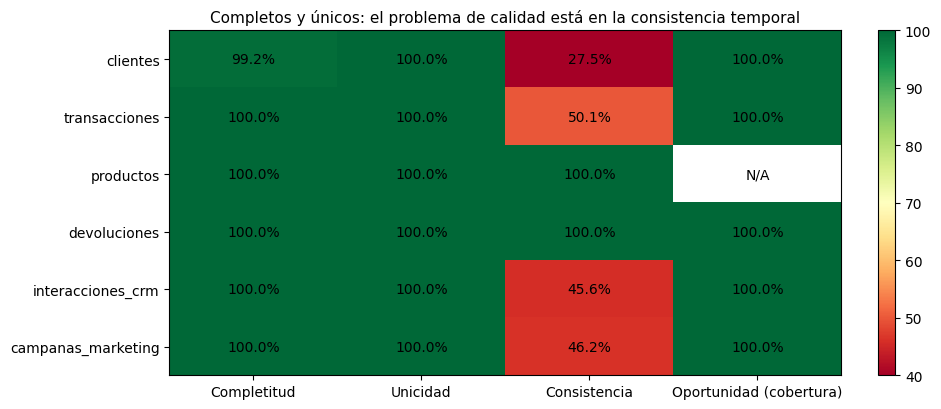

In [18]:
# Mapa de calor de las cuatro dimensiones: hace visible de un golpe que el problema
# es la consistencia y no la completitud ni la unicidad. Escala fija 40–100 % para
# que las celdas sean comparables; 'N/A' donde la dimensión no aplica (productos).
dims = ['completitud_%', 'unicidad_%', 'consistencia_%', 'cobertura_%']
fig, ax = plt.subplots(figsize=(9.5, 4.2))
datos = calidad[dims].astype(float)
im = ax.imshow(datos.values, cmap='RdYlGn', vmin=40, vmax=100, aspect='auto')
ax.set_xticks(range(4), ['Completitud', 'Unicidad', 'Consistencia', 'Oportunidad (cobertura)'])
ax.set_yticks(range(len(calidad)), calidad.index)
for (r, c_), v in np.ndenumerate(datos.values):
    ax.text(c_, r, 'N/A' if np.isnan(v) else f'{v:.1f}%', ha='center', va='center', fontsize=10)
ax.set_title('Completos y únicos: el problema de calidad está en la consistencia temporal', fontsize=11)
plt.colorbar(im, ax=ax, fraction=.03); plt.tight_layout(); guardar_figura(fig, 'a1_metricas_calidad.png'); plt.show()

**Lectura de las cuatro dimensiones:**

- **Completitud y unicidad: prácticamente 100 %** en los seis datasets. No hay nulos explícitos, el único nulo disfrazado es `genero = "No especificado"` (que se conserva como categoría) y no hay claves repetidas ni duplicados lógicos salvo el doble envío de campaña.
- **Consistencia: es la dimensión que falla.** Casi toda la brecha la produce un solo atributo, `clientes.fecha_registro`, que contamina clientes, transacciones, CRM y campañas. Al excluir las reglas de fecha de alta, todos los datasets suben a ~95 % o más, salvo campañas, que sigue penalizada por R19 y R21 (conversiones no verificables y descuentos que no coinciden).
- **Oportunidad: la cobertura es total** (todas las fechas caen dentro de la ventana 2023-01-01 – 2024-12-31) y la frescura es de 0 días en los cuatro datasets con eventos. Lo que falla es la **latencia**: una parte de las devoluciones y de las respuestas de CRM incumple su SLA, que es precisamente lo que analiza A3.
- **Conclusión:** los datos sirven para el análisis, pero hay que tratar con cautela dos campos (`fecha_registro` y `convertido`) y marcar los casos que incumplen SLA. Ninguna decisión de A2–A4 debería apoyarse en `fecha_registro` en bruto.

## 6. Limpieza y transformación
**Objetivo:** producir las tablas limpias que consumen A2–A4 **sin perder registros** y dejando cada decisión explícita. La limpieza solo (i) **marca** lo dudoso con `flag_*`, (ii) **corrige** una inconsistencia semántica demostrable (felicitaciones con estado de resolución) y (iii) **deriva** las columnas que el análisis necesita. Los DataFrames crudos no se tocan: se trabaja sobre copias.

Las dos medidas que no vienen en el origen y que sostienen A2–A3:

$$\text{margen\_bruto}=\text{monto\_neto}-\text{cantidad}\times\text{costo}\qquad \text{margen\_neto}=\text{margen\_bruto}-\text{monto\_devuelto}+\text{costo\_recuperado}$$

donde `costo_recuperado` es el costo de la mercancía devuelta que reingresa al inventario (todos los motivos salvo `Producto_defectuoso` y `Fraude_reportado`). Se conserva además el escenario **pesimista** (`margen_neto_pesimista`), que supone que nada se recupera.

In [19]:
# ---------- Productos ----------
prod_c = prod.copy()
prod_c['margen_unitario'] = (prod_c.precio_lista - prod_c.costo).round(2)   # margen por unidad de catálogo

# ---------- Transacciones (tabla de hechos) ----------
# Se enriquece la venta con el catálogo y se derivan las medidas de rentabilidad.
# Todas las columnas nuevas son aditivas: no se sobrescribe ninguna original.
trx_c = trx.merge(prod_c[['producto_id', 'categoria', 'subcategoria', 'costo']], on='producto_id', how='left')
trx_c['ingreso_bruto'] = (trx_c.cantidad * trx_c.precio_unitario).round(2)      # a precio de lista
trx_c['descuento_monto'] = (trx_c.ingreso_bruto - trx_c.monto_neto).round(2)
trx_c['costo_total'] = (trx_c.cantidad * trx_c.costo).round(2)
trx_c['margen_bruto'] = (trx_c.monto_neto - trx_c.costo_total).round(2)
trx_c['margen_bruto_pct'] = (trx_c.margen_bruto / trx_c.monto_neto * 100).round(2)
# Devolución imputada a la línea de venta: flag + monto + motivo (§6, tabla de decisiones).
trx_c['flag_devuelta'] = trx_c.transaccion_id.isin(dev.transaccion_id).astype(int)
trx_c['monto_devuelto'] = trx_c.transaccion_id.map(dev.set_index('transaccion_id').monto_devuelto).fillna(0)
motivo = trx_c.transaccion_id.map(dev.set_index('transaccion_id').motivo)
trx_c['motivo_devolucion'] = motivo
recuperable = motivo.notna() & ~motivo.isin(MOTIVOS_NO_RECUPERABLES)   # el producto vuelve al inventario
trx_c['costo_recuperado'] = np.where(recuperable, trx_c.costo_total, 0)
trx_c['margen_neto'] = (trx_c.margen_bruto - trx_c.monto_devuelto + trx_c.costo_recuperado).round(2)
trx_c['margen_neto_pesimista'] = (trx_c.margen_bruto - trx_c.monto_devuelto).round(2)   # nada se recupera
# Flags de las inconsistencias detectadas en §4: se marcan, no se eliminan.
trx_c['flag_antes_registro'] = (trx_c.fecha.values < trx_c.cliente_id.map(reg_crudo).values).astype(int)
trx_c['flag_outlier_monto'] = (trx_c.monto_neto > LIM_MONTO).astype(int)
trx_c['anio_mes'] = trx_c.fecha.dt.to_period('M').astype(str)          # clave para dim_fecha
trx_c = trx_c.drop(columns='costo')                                    # el costo ya está en costo_total

In [20]:
# ---------- Clientes ----------
cli_c = cli.copy()
# Primer evento observado del cliente (compra, interacción o envío de campaña):
# es la referencia para decidir si fecha_registro es anterior a la actividad real.
primeros = pd.concat([trx[['cliente_id', 'fecha']], crm[['cliente_id', 'fecha']],
                      cam[['cliente_id', 'fecha_envio']].rename(columns={'fecha_envio': 'fecha'})]).groupby('cliente_id').fecha.min()
cli_c['primera_compra'] = cli_c.cliente_id.map(primera_compra)
cli_c['ultima_compra'] = cli_c.cliente_id.map(trx.groupby('cliente_id').fecha.max())
# Corrección de la inconsistencia de §4.3: el alta efectiva es la más temprana entre
# lo declarado y el primer evento; con ella R03/R07/R16/R20 dejan de fallar (§6.1).
cli_c['fecha_alta_efectiva'] = pd.concat([cli_c.fecha_registro, cli_c.cliente_id.map(primeros)], axis=1).min(axis=1)
cli_c['antiguedad_dias'] = (FECHA_CORTE - cli_c.fecha_alta_efectiva).dt.days
cli_c['flag_registro_inconsistente'] = (cli_c.primera_compra < cli_c.fecha_registro).astype(int)
cli_c['flag_sin_compras'] = cli_c.primera_compra.isna().astype(int)
cli_c['rango_edad'] = pd.cut(cli_c.edad, BINS_EDAD, labels=ETIQ_EDAD)   # cortes declarados en §0

In [21]:
# ---------- Devoluciones ----------
# Se le añade el contexto de la venta (fecha, producto, categoría, canal) para que A3
# no tenga que repetir el join; 'fecha' se renombra para no confundirla con la devolución.
dev_c = dev.merge(trx_c[['transaccion_id', 'fecha', 'producto_id', 'categoria', 'canal', 'monto_neto']], on='transaccion_id', how='left')
dev_c = dev_c.rename(columns={'fecha': 'fecha_compra'})
dev_c['dias_a_devolucion'] = (dev_c.fecha_devolucion - dev_c.fecha_compra).dt.days
dev_c['segmento'] = dev_c.cliente_id.map(cli.set_index('cliente_id').segmento)

# ---------- CRM ----------
crm_c = crm.copy()
crm_c.loc[crm_c.tipo == 'felicitacion', 'resolucion'] = 'no_aplica'     # corrección semántica (R15)
P_WINS = crm_c.tiempo_respuesta_hrs.quantile(Q_WINS)
crm_c['tiempo_respuesta_wins'] = crm_c.tiempo_respuesta_hrs.clip(upper=P_WINS).round(1)   # protege los promedios
crm_c['flag_respuesta_extrema'] = (crm_c.tiempo_respuesta_hrs > SLA_CRM_HRS).astype(int)
crm_c['flag_no_resuelta'] = crm_c.resolucion.isin(['sin_resolver', 'escalado', 'parcialmente_resuelto']).astype(int)

# ---------- Campañas ----------
cam_c = cam.copy()
cam_c['monto_compra_30d'] = cam_c.campana_id.map(cx.groupby('campana_id').monto_neto.sum()).fillna(0).round(2)
cam_c['flag_compra_30d'] = cam_c.campana_id.isin(cam_con_compra).astype(int)
cam_c['flag_conversion_verificada'] = ((cam_c.convertido == 1) & (cam_c.flag_compra_30d == 1)).astype(int)
cam_c['flag_envio_duplicado'] = cam_c.duplicated(['cliente_id', 'tipo_campana', 'fecha_envio'], keep=False).astype(int)
cam_c['segmento'] = cam_c.cliente_id.map(cli.set_index('cliente_id').segmento)

# ---------- Dimensión fecha (calendario de la ventana de análisis) ----------
# Un día por fila: es la dimensión que permite agrupar por mes, trimestre o fin de semana.
dim_fecha = pd.DataFrame({'fecha': pd.date_range(FECHA_INICIO, FECHA_CORTE)})
dim_fecha['fecha_id'] = dim_fecha.fecha.dt.strftime('%Y%m%d').astype(int)    # clave natural AAAAMMDD
dim_fecha['anio'] = dim_fecha.fecha.dt.year; dim_fecha['trimestre'] = dim_fecha.fecha.dt.quarter
dim_fecha['mes'] = dim_fecha.fecha.dt.month; dim_fecha['anio_mes'] = dim_fecha.fecha.dt.to_period('M').astype(str)
dim_fecha['dia_semana'] = dim_fecha.fecha.dt.dayofweek; dim_fecha['es_fin_semana'] = (dim_fecha.dia_semana >= 5).astype(int)

salidas = {'dim_cliente': cli_c, 'dim_producto': prod_c, 'dim_fecha': dim_fecha, 'fact_ventas': trx_c,
           'fact_devoluciones': dev_c, 'fact_interacciones': crm_c, 'fact_campanas': cam_c}

# ---------- Validaciones inmediatas de la transformación ----------
# Si alguna falla, el notebook se detiene aquí y no se exporta nada (§7).
assert trx_c.transaccion_id.is_unique and len(trx_c) == len(trx), 'la limpieza no debe perder ni duplicar transacciones'
assert len(cli_c) == len(cli) and len(dev_c) == len(dev) and len(crm_c) == len(crm) and len(cam_c) == len(cam)
assert np.isclose(trx_c.monto_devuelto.sum(), dev.monto_devuelto.sum()), 'monto devuelto no concilia'
assert np.isclose(trx_c.margen_bruto.sum(), (trx_c.monto_neto - trx_c.costo_total).sum())
assert (crm_c.query("tipo == 'felicitacion'").resolucion == 'no_aplica').all()
assert (cli_c.fecha_alta_efectiva <= cli_c.fecha_registro).all()

# Reconciliación como tabla (no como texto de consola): los asserts de arriba ya
# garantizan que no se perdió ningún registro y que los montos cuadran con el origen.
display(pd.DataFrame({'concepto': ['ingreso_neto_USD', 'margen_bruto_USD', 'margen_bruto_%', 'devuelto_USD'],
                      'valor': [trx_c.monto_neto.sum(), trx_c.margen_bruto.sum(),
                                trx_c.margen_bruto.sum() / trx_c.monto_neto.sum() * 100, trx_c.monto_devuelto.sum()]}
                     ).set_index('concepto').T.round(2))

concepto,ingreso_neto_USD,margen_bruto_USD,margen_bruto_%,devuelto_USD
valor,17392987.48,4310329.05,24.78,2534466.22


**Validación de la transformación.** Antes de medir el efecto de la limpieza, las aserciones de la celda anterior comprueban que no se pierde ni se duplica ningún registro y que los montos concilian con el origen: ingreso neto **17.392.987 USD**, margen bruto **4.310.329 USD (24,8 %)** y **2.534.466 USD** devueltos. Ninguna tabla de `data/clean/` se escribe hasta el §7.

### 6.1 Efecto de la limpieza: calidad antes vs. después
Se reaplican **las mismas verificaciones y métricas** al dato limpio, usando solo las columnas originales (así la comparación es justa) y sustituyendo `fecha_registro` por `fecha_alta_efectiva` en las reglas de fecha de alta. La limpieza **no maquilla** lo que viene mal de origen: R19 y R21 siguen fallando porque `convertido` y `descuento_ofrecido` no se modifican; esos casos quedan **marcados** (`flag_*`) como limitación del dato.

In [22]:
# Se repite EXACTAMENTE el mismo procedimiento del §4, pero sobre las columnas
# originales de las tablas limpias y con fecha_alta_efectiva como fecha de alta.
# Usar solo columnas originales es lo que hace justa la comparación.
reg_limpio = cli_c.set_index('cliente_id').fecha_alta_efectiva
d_cli, d_trx, d_prod, d_dev, d_crm, d_cam = (cli_c[cli.columns], trx_c[trx.columns], prod_c[prod.columns],
                                              dev_c[dev.columns], crm_c[crm.columns], cam_c[cam.columns])
reglas_l, aplic_l, aux_l = construir_reglas(d_cli, d_trx, d_prod, d_dev, d_crm, d_cam, reg_limpio)
fk_l = integridad(d_cli, d_trx, d_prod, d_dev, d_crm, d_cam)
limpio = {'clientes': d_cli, 'transacciones': d_trx, 'productos': d_prod, 'devoluciones': d_dev,
          'interacciones_crm': d_crm, 'campanas_marketing': d_cam}
calidad_l = calcular_calidad(limpio, reglas_l, fk_l, aux_l['dv'], NULOS_DISFRAZADOS).round(2)

# Comparación lado a lado de las métricas del §5: misma función, dos insumos.
cols = ['completitud_%', 'unicidad_%', 'consistencia_%', 'consistencia_sin_fecha_alta_%', 'cobertura_%']
antes_despues = pd.DataFrame({f'{c} {k}': (calidad if k == 'antes' else calidad_l)[c] for c in cols for k in ('antes', 'después')})
guardar_tabla(antes_despues.reset_index(), 'a1_calidad_antes_despues.csv')
display(antes_despues)

,completitud_% antes,completitud_% después,unicidad_% antes,unicidad_% después,consistencia_% antes,consistencia_% después,consistencia_sin_fecha_alta_% antes,consistencia_sin_fecha_alta_% después,cobertura_% antes,cobertura_% después
dataset,,,,,,,,,,
clientes,99.23,99.23,100.00,100.00,27.46,100.00,100.00,100.00,100.0,100.0
transacciones,100.00,100.00,100.00,100.00,50.06,100.00,100.00,100.00,100.0,100.0
productos,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,NaN,NaN
devoluciones,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.0,100.0
interacciones_crm,100.00,100.00,100.00,100.00,45.64,100.00,95.03,100.00,100.0,100.0
campanas_marketing,100.00,100.00,99.99,99.99,46.21,91.11,91.11,91.11,100.0,100.0


**Qué cambia y qué no.** De las 7 verificaciones que fallaban en el crudo, **5 desaparecen** al evaluarlas contra `fecha_alta_efectiva` o al corregir la semántica de las felicitaciones: R03 (5.803 → 0), R07 (24.972 → 0), R15 (233 → 0), R16 (2.428 → 0) y R20 (4.421 → 0). La consistencia de `clientes` y de `transacciones` pasa de 27,46 % y 50,06 % a **100 %**.

**Las dos que persisten no son un defecto de la limpieza**, sino del dato de origen: R19 (618 conversiones declaradas sin compra atribuible) y R21 (166 conversiones cuyo descuento aplicado no coincide con el ofrecido). Corregirlas exigiría inventar información, así que se quedan visibles y marcadas con `flag_conversion_verificada`. Las dos tablas siguientes muestran primero las que cambian y después las que siguen fallando.

In [23]:
# Verificaciones cuyo resultado cambia: se comparan las dos tablas por (dataset, regla)
# y se conservan solo las filas en las que el número de incumplimientos se movió.
tl = tabla_de_reglas(reglas_l, aplic_l)
cmp_reglas = tabla_reglas.merge(tl, on=['dataset', 'regla'], suffixes=('_antes', '_despues'))
cmp_reglas = cmp_reglas[cmp_reglas['incumplen_antes'] != cmp_reglas['incumplen_despues']][['dataset', 'regla', 'incumplen_antes', 'incumplen_despues']]
display(cmp_reglas)

# Las que persisten solo pueden ser las que dependen de columnas que la limpieza no
# toca (convertido y descuento_ofrecido): limitaciones del dato de origen, marcadas.
display(tl.query('incumplen > 0')[['dataset', 'regla', 'incumplen']])

,dataset,regla,incumplen_antes,incumplen_despues
2,clientes,R03 fecha de alta ≤ primera compra,5803,0
6,transacciones,R07 fecha de compra ≥ fecha de alta del cliente,24972,0
19,interacciones_crm,R15 felicitación sin estado de resolución,233,0
20,interacciones_crm,R16 fecha ≥ fecha de alta del cliente,2428,0
25,campanas_marketing,R20 fecha_envio ≥ fecha de alta del cliente,4421,0


,dataset,regla,incumplen
24,campanas_marketing,R19 convertido ⇒ compra en ≤30 días tras el envío,618
26,campanas_marketing,R21 descuento ofrecido = descuento aplicado (conversión verificable),166


**Lectura:** la mejora se concentra donde las verificaciones de **fecha de alta** pasan a evaluarse contra `fecha_alta_efectiva` (clientes, transacciones, CRM y campañas). Lo que no mejora, R19 y R21 en campañas, es una limitación del dato de origen que se **documenta y se marca**, no se corrige: esa es la diferencia entre limpiar y maquillar. La completitud y la unicidad no cambian porque no se imputa ni se elimina ningún registro.

### 6.2 Decisiones de limpieza y su justificación
Las cifras de la tabla se **calculan en esta ejecución** (no están tecleadas) y cada decisión incluye la verificación que la respalda.

In [24]:
# Cifras que alimentan la tabla de decisiones: todas se recalculan aquí (ninguna está
# tecleada) para que la justificación y el número salgan siempre de la misma ejecución.
n_gen = int((cli.genero == 'No especificado').sum())
n_reg_cli = int(cli_c.flag_registro_inconsistente.sum()); n_sin = int(cli_c.flag_sin_compras.sum())
n_antes = int(trx_c.flag_antes_registro.sum()); n_out = int(trx_c.flag_outlier_monto.sum())
n_felic = int((crm.tipo == 'felicitacion').sum()); n_ext = int(crm_c.flag_respuesta_extrema.sum())
n_conv_sin = int(((cam_c.convertido == 1) & (cam_c.flag_compra_30d == 0)).sum()); n_dup = int(cam_c.flag_envio_duplicado.sum())
ids_dup = ', '.join(sorted(cam_c.loc[cam_c.flag_envio_duplicado == 1, 'cliente_id'].unique()))

# Una fila por problema: qué se detectó, qué se decidió, por qué y con qué se verifica.
# La columna 'verificación' remite al punto del notebook donde se comprueba la decisión.
decisiones = pd.DataFrame([
    ('clientes', f'genero = "No especificado" ({n_gen:,}; {n_gen / len(cli):.1%})', 'Conservar como categoría propia; no imputar',
     'No es inferible desde otras variables; imputar introduciría un sesgo.', 'Se conserva como nivel propio en dim_cliente y A2 lo trata como una categoría más.'),
    ('clientes', f'fecha_registro posterior a la primera compra ({n_reg_cli:,} clientes)', 'Conservar; crear fecha_alta_efectiva = mín(registro, primer evento) y antiguedad_dias',
     'Eliminar invalidaría ~la mitad de las ventas; la actividad transaccional es más confiable que un campo de alta formal.',
     'assert fecha_alta_efectiva ≤ fecha_registro; con el alta efectiva R03/R07/R16/R20 dejan de incumplirse (§6.1).'),
    ('clientes', f'{n_sin:,} clientes sin compras', 'Conservar; flag_sin_compras',
     'Son relevantes para marketing (reciben campañas) y para el análisis de churn.', 'len(dim_cliente) = len(clientes).'),
    ('transacciones', f'{n_antes:,} compras anteriores a fecha_registro', 'Conservar; flag_antes_registro',
     'El error está en el atributo del cliente, no en la transacción.', 'dim_producto/fact_ventas conservan todas las filas (§7).'),
    ('transacciones', f'Outliers de monto_neto por IQR ({n_out:,})', 'Conservar; flag_outlier_monto',
     'Ventas legítimas de alto valor (sobre todo Electrónica); el monto reconstruido cuadra exactamente.', 'Todos los outliers cumplen R05 (§3.2).'),
    ('transacciones', 'Variables derivadas de rentabilidad', 'ingreso_bruto, descuento_monto, costo_total, margen_bruto, margen_bruto_pct, flag_devuelta, monto_devuelto, margen_neto y margen_neto_pesimista',
     'El margen no viene en las transacciones y es la base de A2 y A3.', 'Σ monto_devuelto concilia con devoluciones.csv; Σ margen_bruto = Σ monto_neto − Σ costo_total.'),
    ('devoluciones', 'Variables derivadas', 'dias_a_devolucion, categoria, canal y segmento',
     'Permite el análisis de patrones de devolución sin repetir joins (A3).', 'R22/R23: devoluciones totales y dentro del plazo de 30 días.'),
    ('interacciones_crm', f'Felicitaciones con estado de resolución ({n_felic:,})', 'resolucion = "no_aplica"',
     'Una felicitación no es un caso a resolver; evita inflar las quejas no resueltas en A3.', 'assert: todas las felicitaciones quedan como no_aplica.'),
    ('interacciones_crm', f'tiempo_respuesta > {SLA_CRM_HRS} h ({n_ext:,})', 'Conservar; flag_respuesta_extrema y tiempo_respuesta_wins (winsorizado al p99)',
     'Son señal válida de mal servicio; la winsorización protege los promedios.', f'p99 = {P_WINS:.1f} h; el valor original se conserva.'),
    ('campanas_marketing', f'convertido = 1 sin compra en ≤{VENTANA_ATRIBUCION_D} días ({n_conv_sin:,})', 'Conservar el flag oficial; crear flag_conversion_verificada y monto_compra_30d',
     'Permite calcular el retorno con compras reales y probar la robustez de las conclusiones de A4.', 'R19 persiste a propósito (§6.1): es limitación del dato, no se maquilla.'),
    ('campanas_marketing', f'Doble envío del mismo tipo y fecha ({n_dup} filas; cliente {ids_dup})', 'Conservar ambos; flag_envio_duplicado',
     'Descuento y resultado distintos: no es un duplicado técnico.', 'PK única y 0 filas idénticas (§2).'),
    ('todas', 'Registros con valores extremos o inconsistentes', 'Marcar, nunca borrar',
     'Un registro eliminado no se puede auditar; el flag deja la decisión en manos de cada análisis.',
     'Validaciones de la §7: claves únicas, integridad referencial y reconciliación de montos.'),
], columns=['dataset', 'problema', 'decisión', 'justificación', 'verificación'])
guardar_tabla(decisiones, 'a1_decisiones_limpieza.csv')
decisiones

,dataset,problema,decisión,justificación,verificación
0,clientes,"genero = ""No especificado"" (433; 5.4%)",Conservar como categoría propia; no imputar,No es inferible desde otras variables; imputar introduciría un sesgo.,Se conserva como nivel propio en dim_cliente y A2 lo trata como una categoría más.
1,clientes,"fecha_registro posterior a la primera compra (5,803 clientes)","Conservar; crear fecha_alta_efectiva = mín(registro, primer evento) y antiguedad_dias",Eliminar invalidaría ~la mitad de las ventas; la actividad transaccional es más confia...,assert fecha_alta_efectiva ≤ fecha_registro; con el alta efectiva R03/R07/R16/R20 deja...
2,clientes,392 clientes sin compras,Conservar; flag_sin_compras,Son relevantes para marketing (reciben campañas) y para el análisis de churn.,len(dim_cliente) = len(clientes).
3,transacciones,"24,972 compras anteriores a fecha_registro",Conservar; flag_antes_registro,"El error está en el atributo del cliente, no en la transacción.",dim_producto/fact_ventas conservan todas las filas (§7).
4,transacciones,"Outliers de monto_neto por IQR (4,138)",Conservar; flag_outlier_monto,Ventas legítimas de alto valor (sobre todo Electrónica); el monto reconstruido cuadra ...,Todos los outliers cumplen R05 (§3.2).
5,transacciones,Variables derivadas de rentabilidad,"ingreso_bruto, descuento_monto, costo_total, margen_bruto, margen_bruto_pct, flag_devu...",El margen no viene en las transacciones y es la base de A2 y A3.,Σ monto_devuelto concilia con devoluciones.csv; Σ margen_bruto = Σ monto_neto − Σ cost...
6,devoluciones,Variables derivadas,"dias_a_devolucion, categoria, canal y segmento",Permite el análisis de patrones de devolución sin repetir joins (A3).,R22/R23: devoluciones totales y dentro del plazo de 30 días.
7,interacciones_crm,Felicitaciones con estado de resolución (233),"resolucion = ""no_aplica""",Una felicitación no es un caso a resolver; evita inflar las quejas no resueltas en A3.,assert: todas las felicitaciones quedan como no_aplica.
8,interacciones_crm,tiempo_respuesta > 168 h (15),Conservar; flag_respuesta_extrema y tiempo_respuesta_wins (winsorizado al p99),Son señal válida de mal servicio; la winsorización protege los promedios.,p99 = 109.3 h; el valor original se conserva.
9,campanas_marketing,convertido = 1 sin compra en ≤30 días (618),Conservar el flag oficial; crear flag_conversion_verificada y monto_compra_30d,Permite calcular el retorno con compras reales y probar la robustez de las conclusione...,"R19 persiste a propósito (§6.1): es limitación del dato, no se maquilla."


## 7. Exportación de las tablas limpias
Esta es **la única sección que escribe en `data/clean/`**. Las siete tablas que consumen A2–A4, con su grano:

| Tabla | Origen | Grano (una fila por…) |
|---|---|---|
| `dim_cliente` | clientes | cliente |
| `dim_producto` | productos | producto |
| `dim_fecha` | calendario generado | día de la ventana 2023-01-01 – 2024-12-31 |
| `fact_ventas` | transacciones | línea de venta (incluye categoría, margen y flags) |
| `fact_devoluciones` | devoluciones | devolución |
| `fact_interacciones` | interacciones_crm | interacción de CRM |
| `fact_campanas` | campanas_marketing | envío de campaña |

*El diagrama del modelo relacional/dimensional se entrega aparte.*

**Resultado de la exportación:** **7 tablas**, **50.000 ventas** y **17.392.987 USD** de ingreso neto. Las validaciones de la última celda releen los CSV desde disco y confirman claves únicas, integridad referencial, montos conciliados al centavo y que **el crudo no cambió**.

In [25]:
# Las siete tablas se escriben con el mismo encoding que se usó para leer y sin índice
# (el índice de pandas no es dato). Es la única escritura en data/clean/ de todo A1.
for n, df in salidas.items():
    df.to_csv(CLEAN / f'{n}.csv', index=False, encoding='utf-8')
pd.DataFrame({n: {'filas': len(df), 'columnas': df.shape[1]} for n, df in salidas.items()}).T

,filas,columnas
dim_cliente,8000,14
dim_producto,318,8
dim_fecha,731,8
fact_ventas,50000,26
fact_devoluciones,6724,13
fact_interacciones,4684,10
fact_campanas,8820,13


In [26]:
# ---------- Validaciones sobre lo exportado: se relee desde disco ----------
# Validar el archivo escrito (no el DataFrame en memoria) es lo que demuestra que la
# exportación no cambió tipos, tamaños ni claves.
L = {n: pd.read_csv(CLEAN / f'{n}.csv') for n in salidas}
v = L['fact_ventas']

assert all(len(L[n]) == len(df) for n, df in salidas.items()), 'una tabla cambió de tamaño al exportar'
assert len(L['dim_fecha']) == (FECHA_CORTE - FECHA_INICIO).days + 1          # calendario completo, sin huecos
assert v.transaccion_id.is_unique and L['dim_cliente'].cliente_id.is_unique and L['dim_producto'].producto_id.is_unique
assert v.cliente_id.isin(L['dim_cliente'].cliente_id).all() and v.producto_id.isin(L['dim_producto'].producto_id).all()
assert L['fact_devoluciones'].transaccion_id.isin(v.transaccion_id).all()
assert L['fact_campanas'].cliente_id.isin(L['dim_cliente'].cliente_id).all()
# Reconciliación de montos contra el CRUDO: los tres totales deben coincidir al centavo.
assert np.isclose(v.monto_neto.sum(), trx.monto_neto.sum(), atol=0.05), 'el ingreso no concilia con el crudo'
assert np.isclose(v.monto_devuelto.sum(), dev.monto_devuelto.sum(), atol=0.05), 'lo devuelto no concilia'
assert np.isclose(v.margen_bruto.sum(), (v.monto_neto - v.costo_total).sum(), atol=0.05)

# El crudo sigue intacto en disco: mismos registros que al cargarlo (§0).
for n, df in raw.items():
    assert len(pd.read_csv(RAW / f'{n}.csv')) == len(df), f'{n}.csv cambió'

# Resumen de la exportación como tabla: es la evidencia de que se escribió y validó.
display(pd.DataFrame({'validación': ['tablas exportadas', 'ventas en fact_ventas', 'ingreso neto (USD)', 'crudo sin cambios'],
                      'resultado': [len(salidas), len(v), round(v.monto_neto.sum(), 2), 'sí']}).set_index('validación').T)

validación,tablas exportadas,ventas en fact_ventas,ingreso neto (USD),crudo sin cambios
resultado,7,50000,17392987.48,sí


## 8. Supuestos y limitaciones
- **`fecha_registro` no es confiable** y se sustituye por `fecha_alta_efectiva` (la fecha más temprana entre el registro y el primer evento). Es una decisión de modelado: si el negocio confirma que el campo es el alta en el programa de fidelización, seguiría siendo válido para ese fin, pero no para medir antigüedad.
- **`convertido` no se corrige.** Se conserva como métrica oficial y se complementa con `flag_conversion_verificada`. La ventana de 30 días es una **convención** parametrizable (`VENTANA_ATRIBUCION_D`), no un hecho del dato.
- **Descuento ofrecido vs. aplicado (R21).** No coinciden en la mayoría de los casos verificables; el retorno de las campañas (A4) debe calcularse con el descuento *ofrecido* como costo implícito y declararse como supuesto.
- **Margen neto.** Depende del supuesto de recuperación del producto devuelto (todos los motivos excepto defecto y fraude). Se conserva `margen_neto_pesimista` para análisis de sensibilidad en A2.
- **SLA asumidos.** Las 168 h de respuesta de CRM y los 30 días de plazo de devolución son umbrales de negocio asumidos; el máximo observado de devolución es exactamente 30 días y pocas respuestas de CRM superan las 168 h.